In [ ]:
//

Objective 1: Decide how to split and validate the development data.

I recommend that we use a time-based split with chronological validation, rather than a random train-test split.

This is an important decision because we're predicting freight load rates for November and December 2025, using historical data from January to October 2025.

In [1]:
from google.colab import files

uploaded = files.upload()


Saving train-test.csv to train-test.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("train-test.csv")

# Parse date column
df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMonthly distribution:")
print(df.groupby(df["date"].dt.to_period("M")).size())

print("\nFirst 5 records:")
display(df.head())

Dataset shape: (48000, 14)

Columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']

Date range:
2025-01-01 00:00:00 to 2025-10-31 00:00:00

Monthly distribution:
date
2025-01    4918
2025-02    4337
2025-03    5036
2025-04    4819
2025-05    4913
2025-06    4783
2025-07    4912
2025-08    4759
2025-09    4670
2025-10    4853
Freq: M, dtype: int64

First 5 records:


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
# January-August: training
# September-October: validation

split_date = pd.Timestamp("2025-09-01")

train_df = df[df["date"] < split_date].copy()
valid_df = df[df["date"] >= split_date].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", valid_df.shape)

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation period:")
print(valid_df["date"].min(), "to", valid_df["date"].max())

Training shape: (38477, 14)
Validation shape: (9523, 14)

Training period:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation period:
2025-09-01 00:00:00 to 2025-10-31 00:00:00


In [4]:
assert train_df["date"].max() < valid_df["date"].min()

assert len(train_df) + len(valid_df) == len(df)

assert set(train_df["load_id"]).isdisjoint(
    set(valid_df["load_id"])
)

print("All split checks passed!")

All split checks passed!


In [5]:
target = "posted_rate"

drop_columns = ["load_id", target]

X_train = train_df.drop(columns=drop_columns)
y_train = train_df[target]

X_valid = valid_df.drop(columns=drop_columns)
y_valid = valid_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (38477, 12)
y_train: (38477,)
X_valid: (9523, 12)
y_valid: (9523,)


In [6]:
folds = [
    ("2025-05-01", "2025-06-01"),
    ("2025-06-01", "2025-07-01"),
    ("2025-07-01", "2025-08-01"),
    ("2025-08-01", "2025-09-01"),
]

for i, (start, end) in enumerate(folds, 1):

    fold_train = df[df["date"] < start].copy()

    fold_valid = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    print(f"\nFold {i}")
    print("Training rows:", len(fold_train))
    print("Validation rows:", len(fold_valid))
    print("Training until:", fold_train["date"].max())
    print("Validation:", start, "to", end)


Fold 1
Training rows: 19110
Validation rows: 4913
Training until: 2025-04-30 00:00:00
Validation: 2025-05-01 to 2025-06-01

Fold 2
Training rows: 24023
Validation rows: 4783
Training until: 2025-05-31 00:00:00
Validation: 2025-06-01 to 2025-07-01

Fold 3
Training rows: 28806
Validation rows: 4912
Training until: 2025-06-30 00:00:00
Validation: 2025-07-01 to 2025-08-01

Fold 4
Training rows: 33718
Validation rows: 4759
Training until: 2025-07-31 00:00:00
Validation: 2025-08-01 to 2025-09-01


In [7]:
# Missing value analysis

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(3)
})

missing = missing.sort_values(
    "Missing_Count",
    ascending=False
)

display(missing)

# Duplicate analysis

print("Duplicate complete rows:", df.duplicated().sum())

print("Duplicate load IDs:", df["load_id"].duplicated().sum())

print("Unique load IDs:", df["load_id"].nunique())

,Missing_Count,Missing_Percentage
market_index,374,0.779
weight,300,0.625
delivery,0,0.000
pickup_lat,0,0.000
load_id,0,0.000
pickup,0,0.000
delivery_lat,0,0.000
pickup_lon,0,0.000
distance,0,0.000
delivery_lon,0,0.000


Duplicate complete rows: 0
Duplicate load IDs: 0
Unique load IDs: 48000


In [8]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

display(
    df[numeric_cols].describe(
        percentiles=[
            0.01, 0.05, 0.25,
            0.50, 0.75, 0.95, 0.99
        ]
    ).T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,28.357650,28.756680,31.98691,35.29479,39.411040,43.438000,44.302960,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-119.795280,-116.702490,-98.40059,-88.08915,-83.285060,-72.180510,-69.500000,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,28.357650,28.756680,31.98691,35.29479,39.411040,43.438000,44.302960,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-119.795280,-116.702490,-98.40059,-87.52871,-83.285060,-72.180510,-69.500000,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,121.899000,236.100000,550.40000,953.30000,1645.525000,2562.300000,3029.304000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,9801.960000,17490.950000,25800.00000,31436.50000,37018.000000,44934.200000,47500.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.782887,0.836265,0.94967,1.05580,1.219590,1.365957,1.407185,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.304657,1.606055,1.89103,2.05575,2.221685,2.550773,2.883951,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,327.168800,599.738500,1251.55500,2030.76000,3330.750000,4953.766500,5972.834000,25533.00000


In [9]:
categorical_cols = [
    "pickup",
    "delivery",
    "equipment"
]

for col in categorical_cols:

    print(f"\nFeature: {col}")
    print("Unique values:", df[col].nunique())

    print("\nValue counts:")
    display(df[col].value_counts().head(15))


Feature: pickup
Unique values: 64

Value counts:


,count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
Richmond,1140
Nashville,1124
Phoenix,1121
Baton Rouge,1115



Feature: delivery
Unique values: 64

Value counts:


,count
delivery,
Lexington,1197
Fort Wayne,1176
Baton Rouge,1167
Bakersfield,1156
Hartford,1143
Oklahoma City,1140
Richmond,1109
Atlanta,1096
Phoenix,1090



Feature: equipment
Unique values: 3

Value counts:


,count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


In [10]:
print("Negative weights:", (df["weight"] < 0).sum())
print("Zero weights:", (df["weight"] == 0).sum())
print("Missing weights:", df["weight"].isna().sum())

print("\nInvalid distances:")
print((df["distance"] <= 0).sum())

print("\nInvalid target rates:")
print((df["posted_rate"] <= 0).sum())

print("\nMissing market indices:")
print(df["market_index"].isna().sum())

Negative weights: 292
Zero weights: 0
Missing weights: 300

Invalid distances:
0

Invalid target rates:
0

Missing market indices:
374


In [11]:
negative_weights = df[df["weight"] < 0]

display(
    negative_weights[
        [
            "load_id",
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "market_index",
            "quote_signal",
            "posted_rate"
        ]
    ].head(20)
)

,load_id,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,1334.2,Reefer,-36559.0,0.96102,2.11777,2831.27
204,TR-000205,Fresno,Tucson,496.2,Dry Van,-26670.0,0.96903,2.13155,1046.92
206,TR-000207,Columbia,Raleigh,411.3,Reefer,-20003.0,0.94800,2.31682,959.15
225,TR-000226,Greensboro,Lubbock,1317.4,Reefer,-23981.0,1.00820,2.13918,2836.00
376,TR-000377,Madison,Providence,1331.1,Dry Van,-41397.0,0.94787,1.91867,2522.54
446,TR-000447,Albuquerque,Albany,2438.3,Reefer,-37215.0,0.96575,1.96959,4841.57
495,TR-000496,Montgomery,Dayton,715.9,Dry Van,-31214.0,0.85153,2.03947,1473.78
641,TR-000642,Tulsa,Indianapolis,582.4,Dry Van,-41023.0,0.81988,2.22721,1264.33
806,TR-000807,Cincinnati,Buffalo,676.1,Dry Van,-28320.0,0.79158,1.95680,1307.76
1093,TR-001094,Cincinnati,Albany,1058.5,Dry Van,-25153.0,0.89891,1.81081,1907.83


In [12]:
print(
    negative_weights["weight"].describe()
)

count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64


In [13]:
# Missing values by month

monthly_missing = df.groupby(
    df["date"].dt.to_period("M")
).agg(
    missing_weight=("weight", lambda x: x.isna().sum()),
    missing_market_index=(
        "market_index",
        lambda x: x.isna().sum()
    )
)

display(monthly_missing)

,missing_weight,missing_market_index
date,,
2025-01,34,36
2025-02,33,36
2025-03,36,44
2025-04,20,31
2025-05,22,43
2025-06,32,42
2025-07,29,36
2025-08,29,33
2025-09,33,31


In [14]:
equipment_missing = df.groupby("equipment").agg(
    missing_weight=("weight", lambda x: x.isna().sum()),
    missing_market_index=(
        "market_index",
        lambda x: x.isna().sum()
    )
)

display(equipment_missing)

,missing_weight,missing_market_index
equipment,,
Dry Van,175,202
Flatbed,55,73
Reefer,70,99


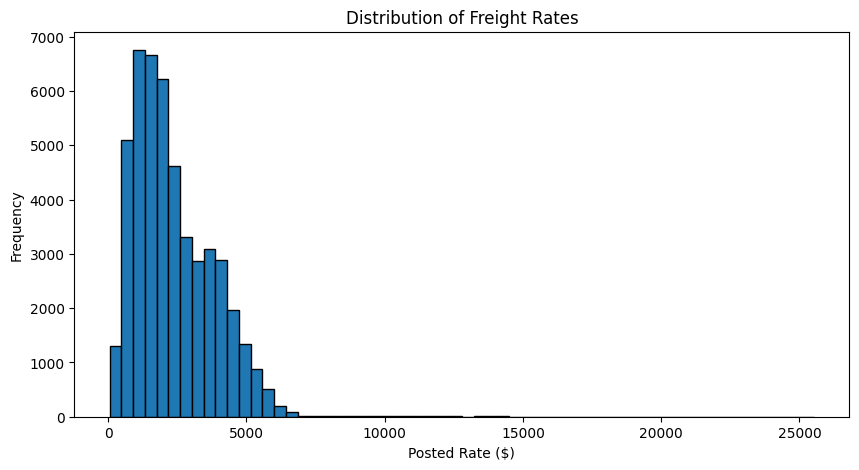

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["posted_rate"],
    bins=60,
    edgecolor="black"
)

plt.xlabel("Posted Rate ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Freight Rates")

plt.show()

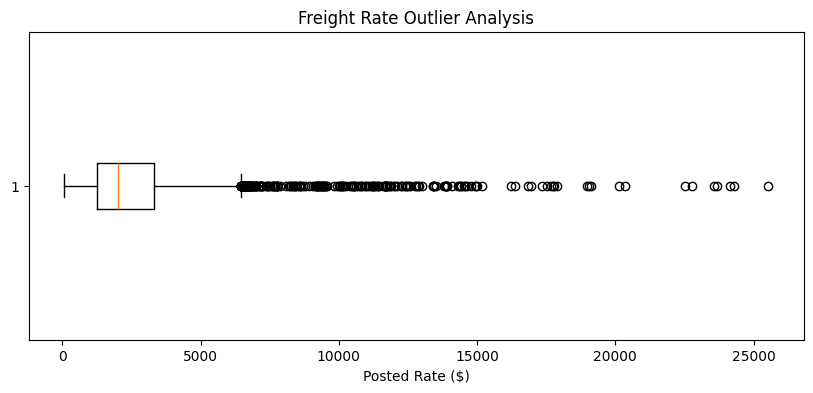

In [16]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["posted_rate"],
    vert=False
)

plt.xlabel("Posted Rate ($)")
plt.title("Freight Rate Outlier Analysis")

plt.show()

In [17]:
q1 = df["posted_rate"].quantile(0.25)
q3 = df["posted_rate"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[
    (df["posted_rate"] < lower_bound) |
    (df["posted_rate"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Outlier observations:", len(outliers))

display(
    outliers.nlargest(15, "posted_rate")[
        [
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "market_index",
            "quote_signal",
            "posted_rate"
        ]
    ]
)

Lower bound: -1867.2375000000006
Upper bound: 6449.5425000000005
Outlier observations: 260


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
12184,Bakersfield,Hartford,2829.8,Dry Van,33153.0,1.16556,1.83188,25533.00
37764,Phoenix,Syracuse,2810.9,Dry Van,33674.0,1.04877,2.16284,24294.98
1466,Los Angeles,Syracuse,2786.0,Reefer,30322.0,0.98678,1.85370,24140.21
17371,Reno,Philadelphia,2777.6,Reefer,33158.0,1.15070,2.15601,23662.71
26235,Charleston,Phoenix,2552.5,Dry Van,25665.0,1.20224,1.81289,23580.42
28219,Tucson,Raleigh,2423.3,Dry Van,30972.0,1.32894,1.97112,22755.66
3353,Phoenix,Charleston,2527.9,Reefer,36840.0,1.03241,2.07342,22534.65
40171,Montgomery,Fresno,2283.4,Dry Van,32447.0,0.98502,1.93645,20361.89
40096,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,1.00464,2.28753,20132.37
47298,Boston,Bakersfield,2979.1,Reefer,30585.0,0.86501,2.09472,19110.30


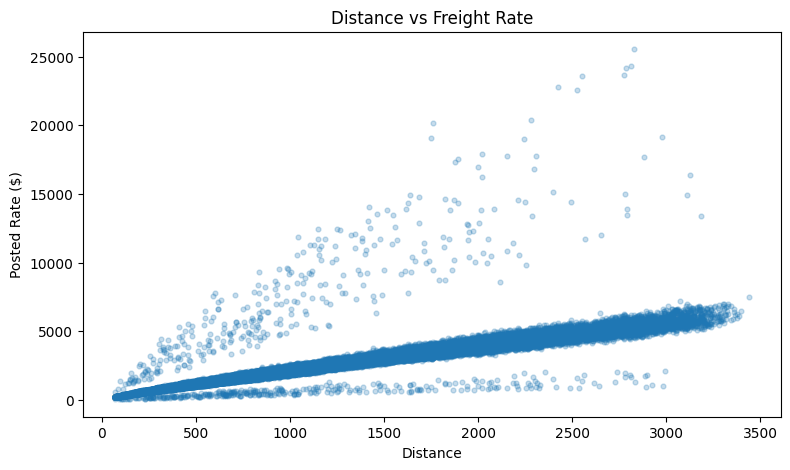

In [18]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["distance"],
    df["posted_rate"],
    alpha=0.25,
    s=12
)

plt.xlabel("Distance")
plt.ylabel("Posted Rate ($)")
plt.title("Distance vs Freight Rate")

plt.show()

,mean,median,count
equipment,,,
Dry Van,2271.548686,1953.035,27202
Flatbed,2445.087223,2076.810,8753
Reefer,2553.636939,2196.670,12045


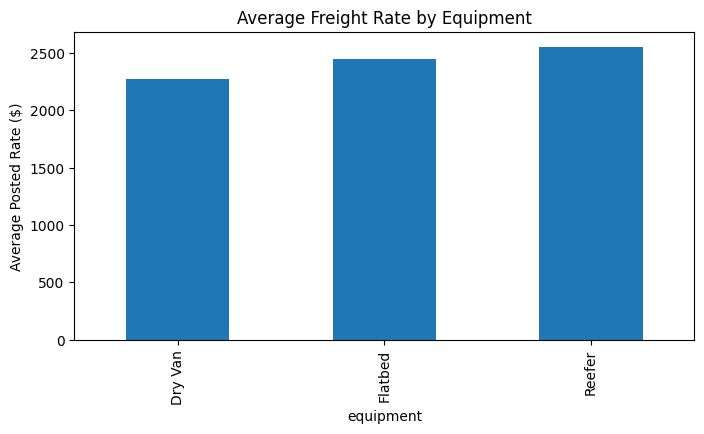

In [19]:
equipment_rates = df.groupby("equipment")[
    "posted_rate"
].agg(["mean", "median", "count"])

display(equipment_rates)

equipment_rates["mean"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Average Freight Rate by Equipment"
)

plt.ylabel("Average Posted Rate ($)")
plt.show()

,mean,median
date,,
2025-01,2255.967048,1915.200
2025-02,2273.804801,1994.250
2025-03,2372.268092,2022.920
2025-04,2372.162308,2044.240
2025-05,2421.776342,2065.510
2025-06,2497.030115,2120.220
2025-07,2415.162030,2059.145
2025-08,2338.407661,2015.730
2025-09,2406.374013,2057.130


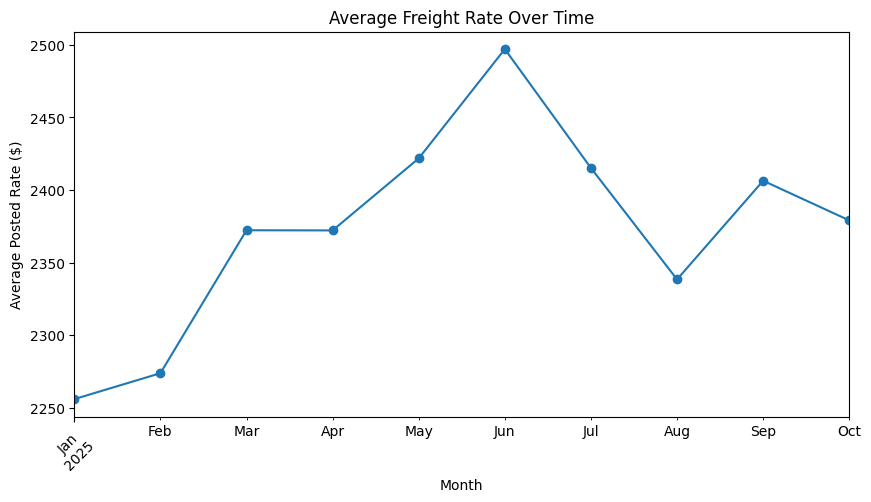

In [20]:
monthly_rates = df.groupby(
    df["date"].dt.to_period("M")
)["posted_rate"].agg(["mean", "median"])

display(monthly_rates)

monthly_rates["mean"].plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Average Freight Rate Over Time")
plt.xlabel("Month")
plt.ylabel("Average Posted Rate ($)")
plt.xticks(rotation=45)

plt.show()

In [21]:
df["weight_status"] = np.select(
    [
        df["weight"].isna(),
        df["weight"] < 0,
        df["weight"] > 0
    ],
    [
        "Missing",
        "Negative",
        "Positive"
    ],
    default="Zero"
)

print(df["weight_status"].value_counts())

weight_comparison = df.groupby(
    "weight_status"
).agg(
    count=("posted_rate", "size"),
    avg_distance=("distance", "mean"),
    avg_rate=("posted_rate", "mean"),
    median_rate=("posted_rate", "median"),
    avg_quote_signal=("quote_signal", "mean"),
    avg_market_index=("market_index", "mean")
)

display(weight_comparison)

weight_status
Positive    47408
Missing       300
Negative      292
Name: count, dtype: int64


,count,avg_distance,avg_rate,median_rate,avg_quote_signal,avg_market_index
weight_status,,,,,,
Missing,300,1145.482000,2350.665767,1984.995,2.072164,1.061744
Negative,292,1120.920205,2389.786233,1994.960,2.041966,1.096322
Positive,47408,1135.887743,2374.030869,2031.440,2.062533,1.083445


In [22]:
df["rate_per_mile"] = (
    df["posted_rate"] / df["distance"]
)

print(df["rate_per_mile"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
1%           1.673521
5%           1.807533
25%          1.986974
50%          2.145348
75%          2.342696
95%          2.735925
99%          3.176940
max         14.125294
Name: rate_per_mile, dtype: float64


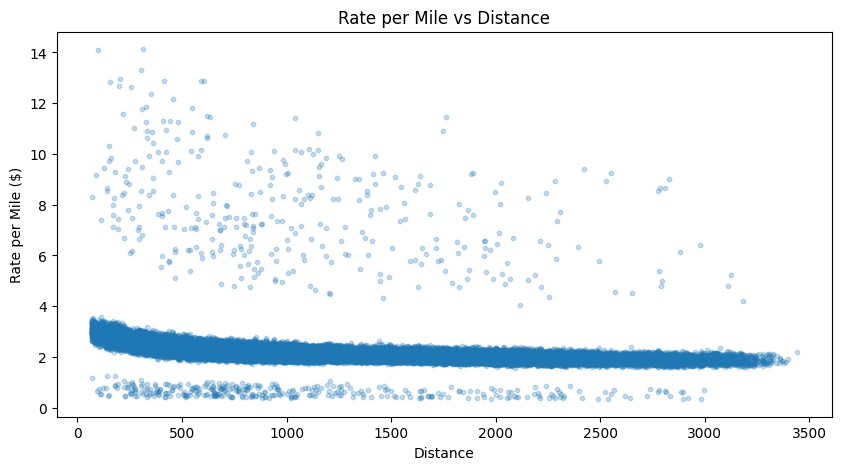

In [23]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["distance"],
    df["rate_per_mile"],
    alpha=0.25,
    s=10
)

plt.xlabel("Distance")
plt.ylabel("Rate per Mile ($)")
plt.title("Rate per Mile vs Distance")

plt.show()

In [24]:
display(
    df.nlargest(20, "rate_per_mile")[
        [
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "market_index",
            "quote_signal",
            "posted_rate",
            "rate_per_mile"
        ]
    ]
)

,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate,rate_per_mile
22254,Greensboro,Cincinnati,314.7,Reefer,-36485.0,1.37257,1.24215,4445.23,14.125294
36609,Chattanooga,Atlanta,98.4,Reefer,22226.0,1.03474,2.58457,1386.42,14.089634
870,Tulsa,Baton Rouge,305.6,Reefer,26447.0,0.80857,2.64181,4069.24,13.315576
17070,Toledo,Dayton,201.5,Flatbed,38714.0,1.30277,1.44259,2609.34,12.949578
27969,Buffalo,Boston,589.9,Reefer,24951.0,1.33920,2.58804,7597.52,12.879335
23369,Amarillo,Lubbock,412.4,Flatbed,35494.0,1.38576,1.40576,5308.96,12.873327
28012,Montgomery,Houston,604.3,Reefer,39690.0,1.31135,2.76111,7773.37,12.863429
45483,Greensboro,Columbia,153.8,Dry Van,34198.0,1.00256,1.46388,1971.21,12.816710
1415,Montgomery,Birmingham,198.2,Reefer,25383.0,0.99663,2.66449,2509.96,12.663774
21968,Jacksonville,Columbia,254.5,Dry Van,32993.0,1.21285,1.52868,3220.66,12.654853


,distance,weight,market_index,quote_signal,posted_rate
distance,1.000000,0.002544,-0.002181,-0.057244,0.908519
weight,0.002544,1.000000,-0.001331,0.008159,0.034840
market_index,-0.002181,-0.001331,1.000000,-0.067827,0.034165
quote_signal,-0.057244,0.008159,-0.067827,1.000000,-0.039858
posted_rate,0.908519,0.034840,0.034165,-0.039858,1.000000


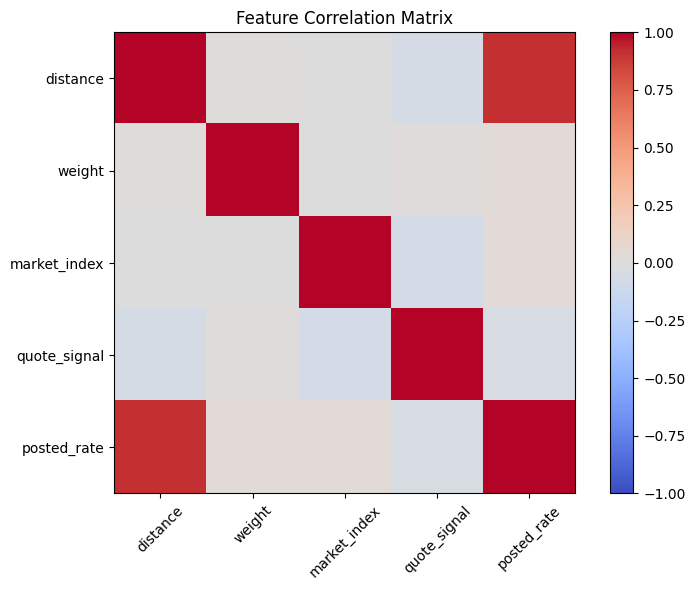

In [25]:
correlation_cols = [
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

corr = df[correlation_cols].corr()

display(corr)

plt.figure(figsize=(8, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(
    range(len(correlation_cols)),
    correlation_cols,
    rotation=45
)

plt.yticks(
    range(len(correlation_cols)),
    correlation_cols
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()



In [26]:
df["high_rate"] = (
    df["posted_rate"] > 6449.54
)

high_rate_summary = df.groupby("equipment").agg(
    total_loads=("posted_rate", "count"),
    high_rate_loads=("high_rate", "sum"),
    average_rate=("posted_rate", "mean")
)

high_rate_summary["high_rate_percentage"] = (
    high_rate_summary["high_rate_loads"] /
    high_rate_summary["total_loads"] * 100
)

display(high_rate_summary)

,total_loads,high_rate_loads,average_rate,high_rate_percentage
equipment,,,,
Dry Van,27202,100,2271.548686,0.367620
Flatbed,8753,51,2445.087223,0.582657
Reefer,12045,109,2553.636939,0.904940


In [27]:
positive = df.loc[df["weight"] > 0, "weight"]
negative_abs = df.loc[df["weight"] < 0, "weight"].abs()

comparison = pd.DataFrame({
    "Positive weights": positive.describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    ),
    "Absolute negative weights": negative_abs.describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    )
})

display(comparison)

,Positive weights,Absolute negative weights
count,47408.000000,292.000000
mean,31415.358674,31724.195205
std,7994.902979,8262.536326
min,5000.000000,5000.000000
10%,21090.400000,21273.400000
25%,25922.000000,25928.500000
50%,31493.500000,31821.500000
75%,37063.000000,37284.250000
90%,41907.000000,43713.100000
max,47500.000000,47500.000000


In [28]:
df["rate_band"] = pd.cut(
    df["rate_per_mile"],
    bins=[0, 1.2, 1.6, 3.5, float("inf")],
    labels=[
        "Low",
        "Lower-middle",
        "Main",
        "High"
    ]
)

band_summary = df.groupby(
    "rate_band",
    observed=False
).agg(
    count=("posted_rate", "size"),
    avg_distance=("distance", "mean"),
    avg_rate=("posted_rate", "mean"),
    avg_quote_signal=("quote_signal", "mean"),
    avg_market_index=("market_index", "mean"),
    avg_weight=("weight", "mean")
)

band_summary["percentage"] = (
    band_summary["count"] / len(df) * 100
)

display(band_summary)

,count,avg_distance,avg_rate,avg_quote_signal,avg_market_index,avg_weight,percentage
rate_band,,,,,,,
Low,335,1075.760896,637.273612,2.045567,1.081544,29678.927711,0.697917
Lower-middle,10,2101.740000,3328.699000,1.699998,0.901436,25791.100000,0.020833
Main,47313,1136.546433,2347.071443,2.062588,1.083481,31041.726178,98.568750
High,342,1071.054678,7769.906228,2.072936,1.077511,30721.479532,0.712500


In [29]:
band_equipment = pd.crosstab(
    df["equipment"],
    df["rate_band"],
    normalize="index"
) * 100

display(band_equipment.round(2))

rate_band,Low,Lower-middle,Main,High
equipment,,,,
Dry Van,0.63,0.03,98.62,0.72
Flatbed,0.72,0.01,98.55,0.72
Reefer,0.84,0.01,98.47,0.68


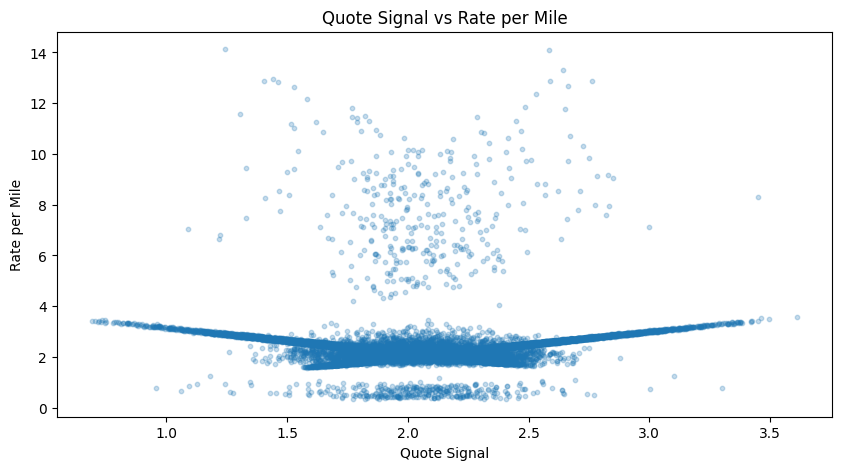

In [30]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["quote_signal"],
    df["rate_per_mile"],
    alpha=0.25,
    s=10
)

plt.xlabel("Quote Signal")
plt.ylabel("Rate per Mile")
plt.title("Quote Signal vs Rate per Mile")

plt.show()

In [31]:
display(
    df.groupby("rate_band", observed=False).agg(
        mean_quote=("quote_signal", "mean"),
        median_quote=("quote_signal", "median"),
        mean_rate=("posted_rate", "mean"),
        count=("posted_rate", "size")
    )
)

,mean_quote,median_quote,mean_rate,count
rate_band,,,,
Low,2.045567,2.049260,637.273612,335
Lower-middle,1.699998,1.588815,3328.699000,10
Main,2.062588,2.055910,2347.071443,47313
High,2.072936,2.032585,7769.906228,342


In [32]:
import numpy as np
import pandas as pd

df_fe = df.copy()

def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius = 3958.8  # miles

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(np.sqrt(a))


df_fe["geo_distance"] = haversine_distance(
    df_fe["pickup_lat"],
    df_fe["pickup_lon"],
    df_fe["delivery_lat"],
    df_fe["delivery_lon"]
)

df_fe["distance_ratio"] = (
    df_fe["distance"] /
    df_fe["geo_distance"].clip(lower=1)
)

df_fe["latitude_difference"] = (
    df_fe["delivery_lat"] - df_fe["pickup_lat"]
)

df_fe["longitude_difference"] = (
    df_fe["delivery_lon"] - df_fe["pickup_lon"]
)

display(
    df_fe[
        [
            "distance",
            "geo_distance",
            "distance_ratio",
            "latitude_difference",
            "longitude_difference"
        ]
    ].describe()
)

,distance,geo_distance,distance_ratio,latitude_difference,longitude_difference
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000
mean,1135.856654,966.154360,1.194681,-0.006370,0.071654
std,728.564416,630.650711,0.143541,6.129317,19.179127
min,70.000000,7.265240,1.058090,-15.945310,-52.198490
25%,550.400000,456.537929,1.164765,-4.347990,-12.031660
50%,953.300000,806.935637,1.182231,-0.025420,0.162800
75%,1645.525000,1410.670791,1.204765,4.416470,12.289240
max,3439.800000,2873.652583,9.634919,15.945310,52.198490


In [33]:
df_fe["month"] = df_fe["date"].dt.month

df_fe["day_of_week"] = df_fe["date"].dt.dayofweek

df_fe["day_of_month"] = df_fe["date"].dt.day

df_fe["is_weekend"] = (
    df_fe["day_of_week"] >= 5
).astype(int)

df_fe["day_of_year"] = df_fe["date"].dt.dayofyear

display(
    df_fe[
        [
            "date",
            "month",
            "day_of_week",
            "day_of_month",
            "is_weekend",
            "day_of_year"
        ]
    ].head(10)
)

,date,month,day_of_week,day_of_month,is_weekend,day_of_year
0,2025-01-01,1,2,1,0,1
1,2025-01-01,1,2,1,0,1
2,2025-01-01,1,2,1,0,1
3,2025-01-01,1,2,1,0,1
4,2025-01-01,1,2,1,0,1
5,2025-01-01,1,2,1,0,1
6,2025-01-01,1,2,1,0,1
7,2025-01-01,1,2,1,0,1
8,2025-01-01,1,2,1,0,1
9,2025-01-01,1,2,1,0,1


In [34]:
df_fe["route"] = (
    df_fe["pickup"].astype(str)
    + "_to_"
    + df_fe["delivery"].astype(str)
)

df_fe["reverse_route"] = (
    df_fe["delivery"].astype(str)
    + "_to_"
    + df_fe["pickup"].astype(str)
)

print("Unique routes:", df_fe["route"].nunique())

print("\nMost common routes:")

display(
    df_fe["route"].value_counts().head(15)
)

Unique routes: 4014

Most common routes:


,count
route,
Columbia_to_Oklahoma City,39
Phoenix_to_Shreveport,39
Lexington_to_Atlanta,39
Fort Wayne_to_Philadelphia,38
Shreveport_to_Hartford,37
Lexington_to_Cincinnati,37
Fort Wayne_to_Hartford,37
Richmond_to_Phoenix,37
Richmond_to_Oklahoma City,37


In [35]:
df_fe["quote_signal_squared"] = (
    df_fe["quote_signal"] ** 2
)

df_fe["log_distance"] = np.log1p(
    df_fe["distance"]
)

df_fe["sqrt_distance"] = np.sqrt(
    df_fe["distance"]
)

df_fe["weight_per_mile"] = (
    df_fe["weight"].abs() /
    df_fe["distance"]
)

display(
    df_fe[
        [
            "distance",
            "log_distance",
            "sqrt_distance",
            "quote_signal",
            "quote_signal_squared",
            "weight_per_mile"
        ]
    ].head()
)

,distance,log_distance,sqrt_distance,quote_signal,quote_signal_squared,weight_per_mile
0,274.3,5.617861,16.562005,2.39595,5.740576,111.768137
1,280.5,5.640132,16.748134,2.43355,5.922166,62.584670
2,967.8,6.876058,31.109484,1.84491,3.403693,32.776400
3,965.4,6.873578,31.070887,1.87712,3.523579,33.491817
4,541.9,6.296925,23.278746,2.56300,6.568969,64.925263


In [36]:
df_fe["weight_missing"] = (
    df_fe["weight"].isna()
).astype(int)

df_fe["market_index_missing"] = (
    df_fe["market_index"].isna()
).astype(int)

df_fe["weight_negative"] = (
    df_fe["weight"] < 0
).astype(int)

print("Weight missing:", df_fe["weight_missing"].sum())
print("Market index missing:", df_fe["market_index_missing"].sum())
print("Negative weight:", df_fe["weight_negative"].sum())

Weight missing: 300
Market index missing: 374
Negative weight: 292


In [37]:
candidate_features = [
    "distance",
    "geo_distance",
    "distance_ratio",
    "latitude_difference",
    "longitude_difference",
    "weight",
    "market_index",
    "quote_signal",
    "quote_signal_squared",
    "log_distance",
    "sqrt_distance",
    "weight_per_mile",
    "month",
    "day_of_week",
    "day_of_month",
    "day_of_year"
]

feature_corr = (
    df_fe[candidate_features + ["posted_rate"]]
    .corr()["posted_rate"]
    .sort_values(ascending=False)
)

display(feature_corr)

,posted_rate
posted_rate,1.000000
distance,0.908519
geo_distance,0.908203
sqrt_distance,0.900569
log_distance,0.853788
weight,0.034840
market_index,0.034165
day_of_year,0.024492
month,0.023804
day_of_month,0.010305


In [38]:
display(
    df_fe.nlargest(15, "distance_ratio")[
        [
            "pickup",
            "delivery",
            "distance",
            "geo_distance",
            "distance_ratio",
            "posted_rate"
        ]
    ]
)

,pickup,delivery,distance,geo_distance,distance_ratio,posted_rate
4140,New Orleans,Shreveport,70.0,7.26524,9.634919,197.06
5091,New Orleans,Shreveport,70.0,7.26524,9.634919,210.14
6960,New Orleans,Shreveport,70.0,7.26524,9.634919,223.52
9348,Shreveport,New Orleans,70.0,7.26524,9.634919,232.33
11949,Shreveport,New Orleans,70.0,7.26524,9.634919,213.59
12480,New Orleans,Shreveport,70.0,7.26524,9.634919,207.13
15756,Shreveport,New Orleans,70.0,7.26524,9.634919,231.24
16351,New Orleans,Shreveport,70.0,7.26524,9.634919,216.61
34136,Shreveport,New Orleans,70.0,7.26524,9.634919,232.27
37183,Shreveport,New Orleans,70.0,7.26524,9.634919,218.90


In [39]:
display(
    df_fe.nlargest(15, "weight_per_mile")[
        [
            "pickup",
            "delivery",
            "distance",
            "weight",
            "weight_per_mile",
            "posted_rate"
        ]
    ]
)

,pickup,delivery,distance,weight,weight_per_mile,posted_rate
9348,Shreveport,New Orleans,70.0,47500.0,678.571429,232.33
24219,Cincinnati,Louisville,70.0,46866.0,669.514286,233.81
40321,Nashville,Chattanooga,71.3,46022.0,645.469846,247.85
46283,Hartford,Philadelphia,74.8,47500.0,635.026738,236.51
5091,New Orleans,Shreveport,70.0,44407.0,634.385714,210.14
25525,Hartford,Philadelphia,70.0,43660.0,623.714286,579.90
6182,Philadelphia,Hartford,70.0,42969.0,613.842857,208.43
45779,Louisville,Cincinnati,70.0,42558.0,607.971429,210.54
11311,Lubbock,Austin,70.0,42249.0,603.557143,240.46
20894,Hartford,Philadelphia,73.0,43835.0,600.479452,214.33


In [40]:
!pip -q install catboost

In [41]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

train_df = df_fe[
    df_fe["date"] < "2025-09-01"
].copy()

valid_df = df_fe[
    df_fe["date"] >= "2025-09-01"
].copy()

print("Training:", train_df.shape)
print("Validation:", valid_df.shape)

Training: (38477, 36)
Validation: (9523, 36)


In [42]:
categorical_features = [
    "pickup",
    "delivery",
    "equipment"
]

numerical_features = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",

    "distance",
    "geo_distance",
    "distance_ratio",
    "latitude_difference",
    "longitude_difference",

    "weight",
    "market_index",
    "quote_signal",

    "log_distance",
    "sqrt_distance",
    "quote_signal_squared",

    "month",
    "day_of_week",
    "day_of_month",
    "day_of_year",
    "is_weekend",

    "weight_missing",
    "market_index_missing",
    "weight_negative"
]

features = categorical_features + numerical_features

target = "posted_rate"

X_train = train_df[features].copy()
X_valid = valid_df[features].copy()

y_train = train_df[target]
y_valid = valid_df[target]

# Treat negative weights as sign errors in this candidate.
# Missing weights remain missing for CatBoost to handle.
X_train.loc[X_train["weight"] < 0, "weight"] = (
    X_train.loc[X_train["weight"] < 0, "weight"].abs()
)

X_valid.loc[X_valid["weight"] < 0, "weight"] = (
    X_valid.loc[X_valid["weight"] < 0, "weight"].abs()
)

# CatBoost expects categorical values as strings.
for col in categorical_features:
    X_train[col] = X_train[col].fillna("Unknown").astype(str)
    X_valid[col] = X_valid[col].fillna("Unknown").astype(str)

print("Features:", len(features))
print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

Features: 26
Training shape: (38477, 26)
Validation shape: (9523, 26)


In [43]:
model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150
)

model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

0:	learn: 1072.9107165	test: 1095.0479954	best: 1095.0479954 (0)	total: 127ms	remaining: 4m 13s
200:	learn: 92.1468066	test: 115.5861327	best: 115.5785488 (199)	total: 15.7s	remaining: 2m 20s
400:	learn: 82.3684220	test: 115.1257317	best: 114.8514828 (340)	total: 30.1s	remaining: 1m 59s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 114.8514828
bestIteration = 340

Shrink model to first 341 iterations.


CatBoostRegressor(depth=8, early_stopping_rounds=150, eval_metric='MAE', iterations=2000, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [44]:
predictions = model.predict(X_valid)

mae = mean_absolute_error(y_valid, predictions)

rmse = np.sqrt(
    mean_squared_error(y_valid, predictions)
)

print("Baseline CatBoost Results")
print("--------------------------")
print(f"MAE:  ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"Best iteration: {model.best_iteration_}")

Baseline CatBoost Results
--------------------------
MAE:  $114.85
RMSE: $635.91
Best iteration: 340


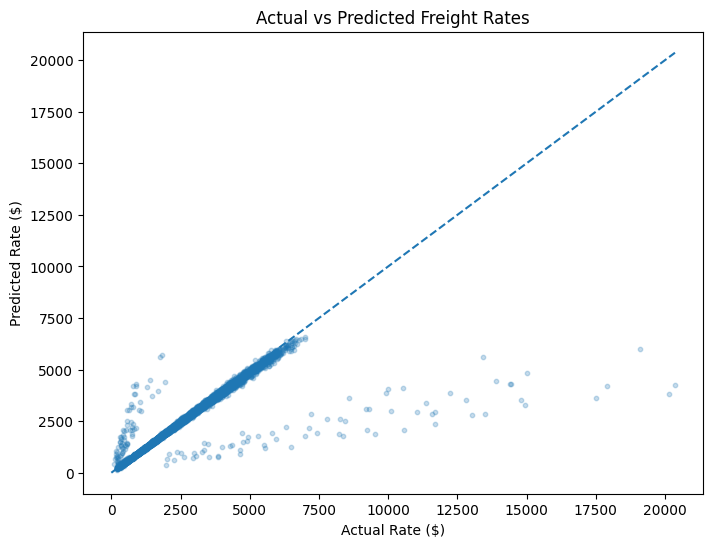

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_valid,
    predictions,
    alpha=0.25,
    s=10
)

limit = max(y_valid.max(), predictions.max())

plt.plot(
    [0, limit],
    [0, limit],
    linestyle="--"
)

plt.xlabel("Actual Rate ($)")
plt.ylabel("Predicted Rate ($)")
plt.title("Actual vs Predicted Freight Rates")

plt.show()

,feature,importance
7,distance,25.258120
8,geo_distance,22.338411
16,sqrt_distance,21.627232
15,log_distance,15.629594
2,equipment,4.986725
17,quote_signal_squared,1.408342
13,market_index,1.320978
14,quote_signal,1.165093
9,distance_ratio,1.116736
12,weight,1.100521


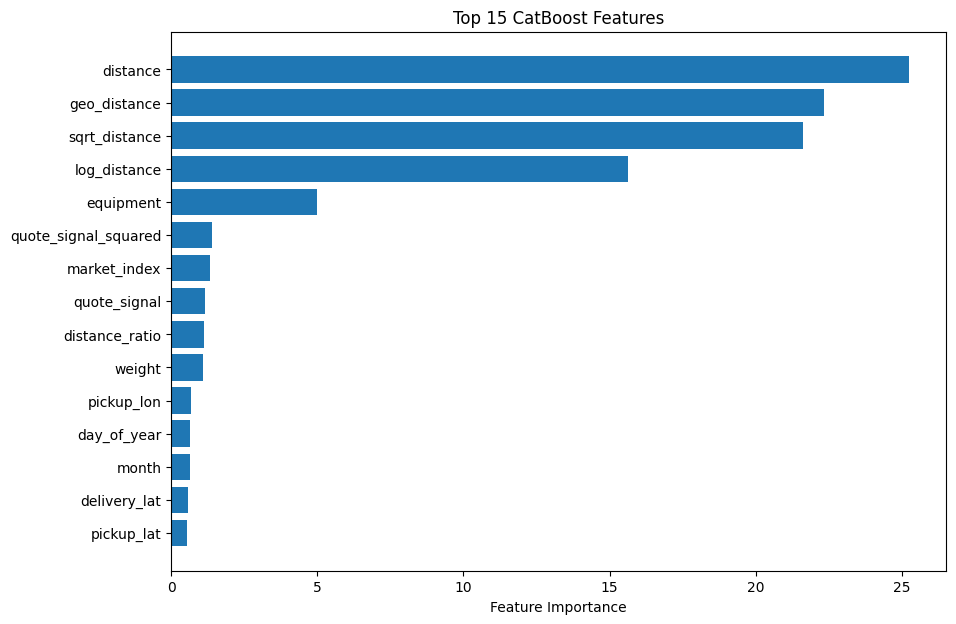

In [46]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 7))

plt.barh(
    importance["feature"].head(15)[::-1],
    importance["importance"].head(15)[::-1]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 CatBoost Features")

plt.show()


In [47]:
error_df = valid_df[[
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "date",
    "posted_rate"
]].copy()

error_df["predicted_rate"] = predictions

error_df["error"] = (
    error_df["posted_rate"] - error_df["predicted_rate"]
)

error_df["absolute_error"] = error_df["error"].abs()

error_df["percentage_error"] = (
    error_df["absolute_error"] /
    error_df["posted_rate"]
) * 100

display(
    error_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(20)
)

,pickup,delivery,distance,equipment,weight,market_index,quote_signal,date,posted_rate,predicted_rate,error,absolute_error,percentage_error
40096,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,1.00464,2.28753,2025-09-11,20132.37,3814.465191,16317.904809,16317.904809,81.053074
40171,Montgomery,Fresno,2283.4,Dry Van,32447.0,0.98502,1.93645,2025-09-11,20361.89,4242.562854,16119.327146,16119.327146,79.164199
43539,Milwaukee,Bakersfield,1893.0,Dry Van,30760.0,1.08079,2.22972,2025-10-03,17514.11,3613.735037,13900.374963,13900.374963,79.366722
46213,Columbia,Tucson,2023.4,Flatbed,34710.0,0.89822,2.06797,2025-10-20,17893.17,4192.246345,13700.923655,13700.923655,76.570690
47298,Boston,Bakersfield,2979.1,Reefer,30585.0,0.86501,2.09472,2025-10-27,19110.30,6003.224126,13107.075874,13107.075874,68.586447
40322,Montgomery,El Paso,1639.9,Dry Van,38363.0,0.96139,1.92501,2025-09-12,14949.25,3275.633833,11673.616167,11673.616167,78.088307
46516,Toledo,Albuquerque,1684.3,Reefer,31536.0,0.98632,2.05917,2025-10-22,14784.38,3536.831527,11247.548473,11247.548473,76.077241
42881,San Antonio,Detroit,1460.5,Dry Van,43567.0,0.74601,2.04253,2025-09-29,13503.63,2843.953693,10659.676307,10659.676307,78.939339
42149,Grand Rapids,Lubbock,1415.5,Dry Van,35333.0,0.96389,2.11162,2025-09-24,13026.22,2793.534707,10232.685293,10232.685293,78.554525
47536,Los Angeles,Richmond,2782.4,Dry Van,25730.0,1.03410,2.39203,2025-10-29,15003.55,4814.398789,10189.151211,10189.151211,67.911602


In [48]:
error_df["rate_band"] = pd.cut(
    error_df["posted_rate"],
    bins=[0, 1000, 2000, 4000, 6000, 10000, float("inf")],
    labels=[
        "Below 1k",
        "1k-2k",
        "2k-4k",
        "4k-6k",
        "6k-10k",
        "Above 10k"
    ]
)

band_analysis = error_df.groupby(
    "rate_band",
    observed=False
).agg(
    count=("posted_rate", "count"),
    actual_mean=("posted_rate", "mean"),
    predicted_mean=("predicted_rate", "mean"),
    MAE=("absolute_error", "mean"),
    RMSE=("error", lambda x: np.sqrt(np.mean(x**2)))
)

display(band_analysis.round(2))

,count,actual_mean,predicted_mean,MAE,RMSE
rate_band,,,,,
Below 1k,1545,697.32,734.46,77.21,305.30
1k-2k,3077,1482.62,1461.32,45.52,167.24
2k-4k,3387,2845.52,2785.93,73.51,166.94
4k-6k,1416,4707.91,4565.48,155.06,382.18
6k-10k,74,6806.47,5205.81,1602.70,2874.04
Above 10k,24,14003.43,3701.80,10301.63,10623.20


In [49]:
print("Actual rates above $6,000:")
print(
    (error_df["posted_rate"] > 6000).sum()
)

print("\nActual rates above $10,000:")
print(
    (error_df["posted_rate"] > 10000).sum()
)

print("\nPredictions above $6,000:")
print(
    (error_df["predicted_rate"] > 6000).sum()
)

print("\nActual vs predicted maximum:")
print("Actual:", error_df["posted_rate"].max())
print("Predicted:", error_df["predicted_rate"].max())

Actual rates above $6,000:
98

Actual rates above $10,000:
24

Predictions above $6,000:
34

Actual vs predicted maximum:
Actual: 20361.89
Predicted: 6598.716226901625


In [50]:
print("TRAINING TARGET DISTRIBUTION")

display(
    train_df["posted_rate"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.995]
    )
)

print("\nVALIDATION TARGET DISTRIBUTION")

display(
    valid_df["posted_rate"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.995]
    )
)

TRAINING TARGET DISTRIBUTION


,posted_rate
count,38477.000000
mean,2369.409512
std,1476.502885
min,57.220000
50%,2026.040000
90%,4350.752000
95%,4930.682000
99%,5968.611200
99.5%,6468.650000
max,25533.000000



VALIDATION TARGET DISTRIBUTION


,posted_rate
count,9523.000000
mean,2392.450169
std,1526.132503
min,104.380000
50%,2044.320000
90%,4426.256000
95%,5044.475000
99%,6030.012800
99.5%,6614.380000
max,20361.890000


In [51]:
error_df["month"] = pd.to_datetime(
    error_df["date"]
).dt.to_period("M")

monthly_errors = error_df.groupby("month").agg(
    count=("posted_rate", "count"),
    MAE=("absolute_error", "mean"),
    RMSE=("error", lambda x: np.sqrt(np.mean(x**2))),
    actual_mean=("posted_rate", "mean"),
    predicted_mean=("predicted_rate", "mean")
)

display(monthly_errors.round(2))

,count,MAE,RMSE,actual_mean,predicted_mean
month,,,,,
2025-09,4670,112.65,619.46,2406.37,2326.45
2025-10,4853,116.97,651.36,2379.05,2295.79


In [52]:
baseline_model = model
baseline_mae = mae
baseline_rmse = rmse

In [53]:
thresholds = [6000, 8000, 10000, 15000]

for threshold in thresholds:

    train_count = (y_train > threshold).sum()
    valid_count = (y_valid > threshold).sum()

    print(f"\nRate above ${threshold:,}")
    print("Training:", train_count)
    print("Validation:", valid_count)


Rate above $6,000
Training: 371
Validation: 98

Rate above $8,000
Training: 107
Validation: 35

Rate above $10,000
Training: 79
Validation: 24

Rate above $15,000
Training: 18
Validation: 6


In [54]:
high_train = train_df[
    train_df["posted_rate"] > 10000
].copy()

high_valid = valid_df[
    valid_df["posted_rate"] > 10000
].copy()

cols = [
    "pickup",
    "delivery",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

print("HIGH-RATE TRAINING OBSERVATIONS")
display(
    high_train[cols].sort_values(
        "posted_rate",
        ascending=False
    ).head(25)
)

print("HIGH-RATE VALIDATION OBSERVATIONS")
display(
    high_valid[cols].sort_values(
        "posted_rate",
        ascending=False
    )
)

HIGH-RATE TRAINING OBSERVATIONS


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
12184,Bakersfield,Hartford,2829.8,Dry Van,33153.0,1.16556,1.83188,25533.00
37764,Phoenix,Syracuse,2810.9,Dry Van,33674.0,1.04877,2.16284,24294.98
1466,Los Angeles,Syracuse,2786.0,Reefer,30322.0,0.98678,1.85370,24140.21
17371,Reno,Philadelphia,2777.6,Reefer,33158.0,1.15070,2.15601,23662.71
26235,Charleston,Phoenix,2552.5,Dry Van,25665.0,1.20224,1.81289,23580.42
28219,Tucson,Raleigh,2423.3,Dry Van,30972.0,1.32894,1.97112,22755.66
3353,Phoenix,Charleston,2527.9,Reefer,36840.0,1.03241,2.07342,22534.65
31259,Oklahoma City,Baltimore,1747.7,Reefer,28876.0,1.34103,1.80406,19042.39
34583,Atlanta,Fresno,2242.0,Dry Van,32005.0,1.09714,1.98678,18972.15
20245,Atlanta,Los Angeles,2153.5,Reefer,31758.0,1.42571,1.96054,17772.53


HIGH-RATE VALIDATION OBSERVATIONS


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
40171,Montgomery,Fresno,2283.4,Dry Van,32447.0,0.98502,1.93645,20361.89
40096,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,1.00464,2.28753,20132.37
47298,Boston,Bakersfield,2979.1,Reefer,30585.0,0.86501,2.09472,19110.30
46213,Columbia,Tucson,2023.4,Flatbed,34710.0,0.89822,2.06797,17893.17
43539,Milwaukee,Bakersfield,1893.0,Dry Van,30760.0,1.08079,2.22972,17514.11
47536,Los Angeles,Richmond,2782.4,Dry Van,25730.0,1.03410,2.39203,15003.55
40322,Montgomery,El Paso,1639.9,Dry Van,38363.0,0.96139,1.92501,14949.25
46516,Toledo,Albuquerque,1684.3,Reefer,31536.0,0.98632,2.05917,14784.38
44267,Albany,Albuquerque,2492.6,Dry Van,25513.0,1.05590,2.38846,14425.42
46366,Bakersfield,Columbia,2251.9,Dry Van,40729.0,0.94743,2.19163,14403.14


In [55]:
train_analysis = train_df.copy()

train_analysis["rate_category"] = np.where(
    train_analysis["posted_rate"] > 10000,
    "Above 10000",
    "Normal"
)

comparison = train_analysis.groupby(
    "rate_category"
).agg(
    count=("posted_rate", "count"),
    avg_rate=("posted_rate", "mean"),
    avg_distance=("distance", "mean"),
    avg_weight=("weight", "mean"),
    avg_market_index=("market_index", "mean"),
    avg_quote_signal=("quote_signal", "mean")
)

display(comparison.round(2))

,count,avg_rate,avg_distance,avg_weight,avg_market_index,avg_quote_signal
rate_category,,,,,,
Above 10000,79,13813.29,1871.99,31594.41,1.15,2.03
Normal,38398,2345.86,1134.49,30990.43,1.12,2.06


In [56]:
high_train["route"] = (
    high_train["pickup"] + " -> " +
    high_train["delivery"]
)

high_valid["route"] = (
    high_valid["pickup"] + " -> " +
    high_valid["delivery"]
)

print("Most common high-rate training routes")

display(
    high_train.groupby("route").agg(
        count=("posted_rate", "size"),
        avg_rate=("posted_rate", "mean"),
        max_rate=("posted_rate", "max")
    ).sort_values(
        "count",
        ascending=False
    ).head(15)
)

print("Most common high-rate validation routes")

display(
    high_valid.groupby("route").agg(
        count=("posted_rate", "size"),
        avg_rate=("posted_rate", "mean"),
        max_rate=("posted_rate", "max")
    ).sort_values(
        "count",
        ascending=False
    ).head(15)
)

Most common high-rate training routes


,count,avg_rate,max_rate
route,,,
Los Angeles -> Mobile,2,11973.790,12284.47
Phoenix -> Jacksonville,2,12695.455,14536.22
Albuquerque -> Indianapolis,1,12100.180,12100.18
Albany -> Shreveport,1,10402.190,10402.19
Albany -> Baton Rouge,1,11408.870,11408.87
Atlanta -> Fresno,1,18972.150,18972.15
Atlanta -> Los Angeles,1,17772.530,17772.53
Bakersfield -> Buffalo,1,15165.130,15165.13
Bakersfield -> Hartford,1,25533.000,25533.00


Most common high-rate validation routes


,count,avg_rate,max_rate
route,,,
Albany -> Albuquerque,1,14425.42,14425.42
Atlanta -> Phoenix,1,13894.55,13894.55
Bakersfield -> Columbia,1,14403.14,14403.14
Baltimore -> Oklahoma City,1,20132.37,20132.37
Boston -> Bakersfield,1,19110.30,19110.30
Boston -> Phoenix,1,13420.59,13420.59
Columbia -> Tucson,1,17893.17,17893.17
Corpus Christi -> Las Vegas,1,11596.28,11596.28
Grand Rapids -> Lubbock,1,13026.22,13026.22


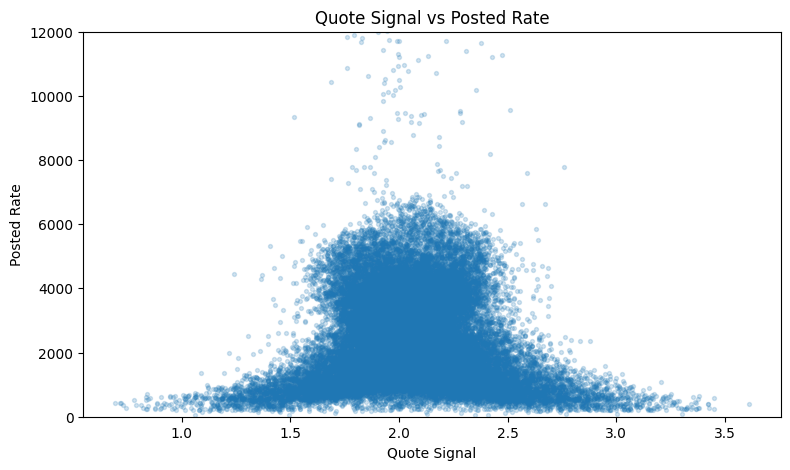

In [57]:
plt.figure(figsize=(9, 5))

plt.scatter(
    train_df["quote_signal"],
    train_df["posted_rate"],
    alpha=0.2,
    s=8
)

plt.xlabel("Quote Signal")
plt.ylabel("Posted Rate")
plt.title("Quote Signal vs Posted Rate")
plt.ylim(0, 12000)

plt.show()

In [58]:

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ----------------------------------
# 1. Define features
# ----------------------------------

features = [
    'pickup', 'delivery', 'equipment',
    'pickup_lat', 'pickup_lon',
    'delivery_lat', 'delivery_lon',
    'distance', 'geo_distance', 'distance_ratio',
    'latitude_difference', 'longitude_difference',
    'weight', 'market_index', 'quote_signal',
    'log_distance', 'sqrt_distance',
    'quote_signal_squared',
    'month', 'day_of_week', 'day_of_month',
    'is_weekend', 'day_of_year',
    'weight_missing', 'market_index_missing',
    'weight_negative'
]

categorical_features = ['pickup', 'delivery', 'equipment']

# ----------------------------------
# 2. Prepare data
# ----------------------------------

X_train = train_df[features].copy()
X_valid = valid_df[features].copy()

y_train = train_df['posted_rate'].copy()
y_valid = valid_df['posted_rate'].copy()

# CatBoost categorical columns must not contain NaN
for col in categorical_features:
    X_train[col] = X_train[col].fillna('Unknown').astype(str)
    X_valid[col] = X_valid[col].fillna('Unknown').astype(str)

# ----------------------------------
# 3. Transform target
# ----------------------------------

y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

# ----------------------------------
# 4. Train model
# ----------------------------------

log_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    early_stopping_rounds=150,
    verbose=200
)

log_model.fit(
    X_train,
    y_train_log,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid_log),
    verbose=200
)

# ----------------------------------
# 5. Predict and reverse transform
# ----------------------------------

pred_log = log_model.predict(X_valid)

predictions = np.expm1(pred_log)
predictions = np.maximum(predictions, 0)

# ----------------------------------
# 6. Evaluation
# ----------------------------------

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

wape = (
    np.sum(np.abs(y_valid - predictions))
    / np.sum(np.abs(y_valid))
) * 100

print("\nLOG TARGET CATBOOST RESULTS")
print("--------------------------------")
print(f"MAE:  ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"WAPE: {wape:.2f}%")
print(f"Best iteration: {log_model.best_iteration_}")


0:	learn: 0.6348445	test: 0.6430867	best: 0.6430867 (0)	total: 92.6ms	remaining: 3m 5s
200:	learn: 0.1495432	test: 0.1607946	best: 0.1607868 (181)	total: 12.4s	remaining: 1m 51s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.1607761083
bestIteration = 220

Shrink model to first 221 iterations.

LOG TARGET CATBOOST RESULTS
--------------------------------
MAE:  $112.97
RMSE: $635.07
WAPE: 4.72%
Best iteration: 220


In [59]:

results = pd.DataFrame({
    'actual': y_valid.values,
    'predicted': predictions
})

results['absolute_error'] = (
    results['actual'] - results['predicted']
).abs()

results['rate_band'] = pd.cut(
    results['actual'],
    bins=[0, 1000, 2000, 4000, 6000, 10000, np.inf],
    labels=[
        'Below 1k',
        '1k-2k',
        '2k-4k',
        '4k-6k',
        '6k-10k',
        'Above 10k'
    ]
)

band_results = results.groupby(
    'rate_band', observed=False
).agg(
    count=('actual', 'count'),
    actual_mean=('actual', 'mean'),
    predicted_mean=('predicted', 'mean'),
    MAE=('absolute_error', 'mean')
)

print(band_results.round(2))


           count  actual_mean  predicted_mean       MAE
rate_band                                              
Below 1k    1545       697.32          743.37     69.07
1k-2k       3077      1482.62         1464.71     45.50
2k-4k       3387      2845.52         2804.05     71.11
4k-6k       1416      4707.91         4575.04    156.68
6k-10k        74      6806.47         5193.31   1613.65
Above 10k     24     14003.43         3713.51  10289.92


In [60]:

from catboost import CatBoostRegressor
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Original target
y_train = train_df['posted_rate']
y_valid = valid_df['posted_rate']

# Give high-rate loads additional importance
sample_weights = np.where(y_train > 6000, 5.0, 1.0)

print("Normal records:", np.sum(sample_weights == 1))
print("High-rate records:", np.sum(sample_weights == 5))

weighted_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function='MAE',
    eval_metric='MAE',
    random_seed=42,
    early_stopping_rounds=150,
    verbose=200
)

weighted_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features,
    sample_weight=sample_weights,
    eval_set=(X_valid, y_valid),
    verbose=200
)

# Predictions
weighted_predictions = weighted_model.predict(X_valid)
weighted_predictions = np.maximum(weighted_predictions, 0)

# Overall metrics
mae = mean_absolute_error(y_valid, weighted_predictions)
rmse = np.sqrt(mean_squared_error(y_valid, weighted_predictions))

print("\nWEIGHTED CATBOOST RESULTS")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Category-wise evaluation
weighted_results = pd.DataFrame({
    'actual': y_valid.values,
    'predicted': weighted_predictions
})

weighted_results['absolute_error'] = (
    weighted_results['actual'] -
    weighted_results['predicted']
).abs()

weighted_results['rate_band'] = pd.cut(
    weighted_results['actual'],
    bins=[0, 1000, 2000, 4000, 6000, 10000, np.inf],
    labels=[
        'Below 1k', '1k-2k', '2k-4k',
        '4k-6k', '6k-10k', 'Above 10k'
    ]
)

print(
    weighted_results.groupby(
        'rate_band', observed=False
    ).agg(
        count=('actual', 'count'),
        actual_mean=('actual', 'mean'),
        predicted_mean=('predicted', 'mean'),
        MAE=('absolute_error', 'mean')
    ).round(2)
)


Normal records: 38106
High-rate records: 371
0:	learn: 1256.6639040	test: 1097.5252260	best: 1097.5252260 (0)	total: 143ms	remaining: 4m 46s
200:	learn: 207.3348603	test: 115.8726307	best: 115.8726307 (200)	total: 15.6s	remaining: 2m 19s
400:	learn: 196.4814030	test: 116.3763101	best: 114.9127328 (284)	total: 30.3s	remaining: 2m
Stopped by overfitting detector  (150 iterations wait)

bestTest = 114.9127328
bestIteration = 284

Shrink model to first 285 iterations.

WEIGHTED CATBOOST RESULTS
-------------------------
MAE: 114.91
RMSE: 635.67
           count  actual_mean  predicted_mean       MAE
rate_band                                              
Below 1k    1545       697.32          734.89     76.09
1k-2k       3077      1482.62         1460.14     47.47
2k-4k       3387      2845.52         2787.38     72.67
4k-6k       1416      4707.91         4565.73    156.33
6k-10k        74      6806.47         5242.11   1567.63
Above 10k     24     14003.43         3703.56  10299.87


In [61]:
# Inspect high-rate records in training data

high_rate = train_df[train_df['posted_rate'] > 6000].copy()

print("High-rate records:", len(high_rate))

display(
    high_rate[
        [
            'pickup', 'delivery', 'distance',
            'equipment', 'weight', 'market_index',
            'quote_signal', 'posted_rate'
        ]
    ].sort_values('posted_rate', ascending=False).head(30)
)

print("\nEquipment distribution:")
display(high_rate['equipment'].value_counts())

print("\nDistance statistics:")
display(high_rate['distance'].describe())

print("\nRate per mile statistics:")
display((high_rate['posted_rate'] / high_rate['distance']).describe())

High-rate records: 371


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
12184,Bakersfield,Hartford,2829.8,Dry Van,33153.0,1.16556,1.83188,25533.00
37764,Phoenix,Syracuse,2810.9,Dry Van,33674.0,1.04877,2.16284,24294.98
1466,Los Angeles,Syracuse,2786.0,Reefer,30322.0,0.98678,1.85370,24140.21
17371,Reno,Philadelphia,2777.6,Reefer,33158.0,1.15070,2.15601,23662.71
26235,Charleston,Phoenix,2552.5,Dry Van,25665.0,1.20224,1.81289,23580.42
28219,Tucson,Raleigh,2423.3,Dry Van,30972.0,1.32894,1.97112,22755.66
3353,Phoenix,Charleston,2527.9,Reefer,36840.0,1.03241,2.07342,22534.65
31259,Oklahoma City,Baltimore,1747.7,Reefer,28876.0,1.34103,1.80406,19042.39
34583,Atlanta,Fresno,2242.0,Dry Van,32005.0,1.09714,1.98678,18972.15
20245,Atlanta,Los Angeles,2153.5,Reefer,31758.0,1.42571,1.96054,17772.53



Equipment distribution:


,count
equipment,
Reefer,180
Flatbed,98
Dry Van,93



Distance statistics:


,distance
count,371.000000
mean,2474.091375
std,848.961141
min,589.900000
25%,1743.800000
50%,2932.800000
75%,3110.450000
max,3439.800000



Rate per mile statistics:


,0
count,371.000000
mean,4.234257
std,2.991908
min,1.840622
25%,2.035271
50%,2.149013
75%,6.651329
max,12.879335


In [62]:
train_df['rate_per_mile'] = (
    train_df['posted_rate'] / train_df['distance']
)

train_df['rate_category'] = np.where(
    train_df['posted_rate'] > 6000,
    'High',
    'Normal'
)

display(
    train_df.groupby('rate_category').agg(
        count=('posted_rate', 'count'),
        mean_rate=('posted_rate', 'mean'),
        median_rate=('posted_rate', 'median'),
        mean_distance=('distance', 'mean'),
        mean_rate_per_mile=('rate_per_mile', 'mean'),
        median_rate_per_mile=('rate_per_mile', 'median')
    )
)

,count,mean_rate,median_rate,mean_distance,mean_rate_per_mile,median_rate_per_mile
rate_category,,,,,,
High,371,8182.337817,6510.96,2474.091375,4.234257,2.149013
Normal,38106,2312.814844,2012.09,1122.981055,2.190820,2.141126


In [63]:

# Compare high-rate records with normal records

import numpy as np
import pandas as pd

df_analysis = df.copy()

df_analysis["rate_per_mile"] = (
    df_analysis["posted_rate"] / df_analysis["distance"]
)

df_analysis["rate_category"] = np.where(
    df_analysis["posted_rate"] > 10000,
    "High",
    "Normal"
)

# Compare rate per mile across distance groups
df_analysis["distance_band"] = pd.cut(
    df_analysis["distance"],
    bins=[0, 500, 1000, 1500, 2000, 2500, 3000, 4000],
    labels=[
        "0-500", "500-1000", "1000-1500",
        "1500-2000", "2000-2500",
        "2500-3000", "3000+"
    ]
)

print("Rate per mile by category:")
display(
    df_analysis.groupby("rate_category", observed=True)
    ["rate_per_mile"]
    .describe()
)

print("\nHigh-rate percentage by distance band:")
display(
    pd.crosstab(
        df_analysis["distance_band"],
        df_analysis["rate_category"],
        normalize="index"
    ).round(4) * 100
)

print("\nHigh-rate records with unusually high rate per mile:")
display(
    df_analysis[
        (df_analysis["rate_category"] == "High")
    ].sort_values("rate_per_mile", ascending=False)[
        ["pickup", "delivery", "distance", "equipment",
         "weight", "market_index", "quote_signal",
         "posted_rate", "rate_per_mile"]
    ].head(20)
)


Rate per mile by category:


,count,mean,std,min,25%,50%,75%,max
rate_category,,,,,,,,
High,103.0,7.675746,1.764063,4.215274,6.289943,7.907356,9.024407,11.436897
Normal,47897.0,2.203605,0.520359,0.333709,1.986607,2.144605,2.341234,14.125294



High-rate percentage by distance band:


rate_category,High,Normal
distance_band,,
0-500,0.00,100.00
500-1000,0.00,100.00
1000-1500,0.33,99.67
1500-2000,0.57,99.43
2000-2500,0.45,99.55
2500-3000,0.61,99.39
3000+,0.53,99.47



High-rate records with unusually high rate per mile:


,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate,rate_per_mile
40096,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,1.00464,2.28753,20132.37,11.436897
22730,Dallas,Grand Rapids,1041.3,Reefer,32899.0,1.24348,1.79121,11895.25,11.423461
31259,Oklahoma City,Baltimore,1747.7,Reefer,28876.0,1.34103,1.80406,19042.39,10.895686
11713,Fort Wayne,Oklahoma City,1151.3,Reefer,38377.0,0.94313,2.31669,12454.19,10.817502
28597,Richmond,Shreveport,1106.1,Reefer,32640.0,1.20681,2.47240,11276.81,10.195109
21702,Buffalo,Shreveport,1151.5,Flatbed,25885.0,1.30036,1.99998,11708.49,10.168033
44344,Lexington,Albany,1040.0,Dry Van,36569.0,1.04012,2.05845,10566.25,10.159856
9999,Grand Rapids,Boston,1069.1,Reefer,29476.0,1.11126,2.04323,10769.23,10.073174
10386,Mobile,Amarillo,1125.8,Dry Van,38863.0,1.13115,2.13355,11247.80,9.990940
9832,El Paso,Shreveport,1252.3,Dry Van,28394.0,1.04073,1.99154,12422.22,9.919524


In [64]:

# High-rate distribution by equipment and distance

df_analysis = df.copy()

df_analysis["rate_per_mile"] = (
    df_analysis["posted_rate"] / df_analysis["distance"]
)

df_analysis["high_rate"] = (
    df_analysis["posted_rate"] > 6000
).astype(int)

print("High-rate percentage by equipment:")
display(
    df_analysis.groupby("equipment").agg(
        total_records=("posted_rate", "size"),
        high_rate_count=("high_rate", "sum"),
        high_rate_percentage=("high_rate", "mean"),
        median_rate=("posted_rate", "median"),
        median_rate_per_mile=("rate_per_mile", "median")
    ).round(3)
)

print("\nHigh-rate percentage by equipment and distance:")
display(
    df_analysis.pivot_table(
        index="equipment",
        columns=pd.cut(
            df_analysis["distance"],
            bins=[0, 1000, 2000, 3000, 4000]
        ),
        values="high_rate",
        aggfunc="mean",
        observed=False
    ).round(4) * 100
)


High-rate percentage by equipment:


,total_records,high_rate_count,high_rate_percentage,median_rate,median_rate_per_mile
equipment,,,,,
Dry Van,27202,124,0.005,1953.035,2.046
Flatbed,8753,123,0.014,2076.810,2.220
Reefer,12045,222,0.018,2196.670,2.312



High-rate percentage by equipment and distance:


distance,"(0, 1000]","(1000, 2000]","(2000, 3000]","(3000, 4000]"
equipment,,,,
Dry Van,0.10,0.75,0.58,7.12
Flatbed,0.17,0.71,1.58,64.96
Reefer,0.20,0.66,3.88,81.82


In [65]:

df_analysis = df.copy()

df_analysis["high_rate"] = (
    df_analysis["posted_rate"] > 6000
).astype(int)

df_analysis["distance_band"] = pd.cut(
    df_analysis["distance"],
    bins=[0, 1000, 2000, 3000, 4000]
)

# Number of records in each equipment-distance combination
counts = pd.crosstab(
    df_analysis["equipment"],
    df_analysis["distance_band"]
)

# Number of high-rate records
high_counts = pd.crosstab(
    df_analysis["equipment"],
    df_analysis["distance_band"],
    values=df_analysis["high_rate"],
    aggfunc="sum"
).fillna(0).astype(int)

# High-rate percentage
percentages = (
    high_counts / counts.replace(0, np.nan) * 100
).round(2)

print("Total records:")
display(counts)

print("High-rate records:")
display(high_counts)

print("High-rate percentages:")
display(percentages)


Total records:


distance_band,"(0, 1000]","(1000, 2000]","(2000, 3000]","(3000, 4000]"
equipment,,,,
Dry Van,14291,8612,3990,309
Flatbed,4689,2684,1263,117
Reefer,6365,3812,1725,143


High-rate records:


distance_band,"(0, 1000]","(1000, 2000]","(2000, 3000]","(3000, 4000]"
equipment,,,,
Dry Van,14,65,23,22
Flatbed,8,19,20,76
Reefer,13,25,67,117


High-rate percentages:


distance_band,"(0, 1000]","(1000, 2000]","(2000, 3000]","(3000, 4000]"
equipment,,,,
Dry Van,0.10,0.75,0.58,7.12
Flatbed,0.17,0.71,1.58,64.96
Reefer,0.20,0.66,3.88,81.82


In [66]:

from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the existing train/validation split
# X_train, X_valid, y_train, y_valid

HIGH_THRESHOLD = 6000

y_train_high = (y_train > HIGH_THRESHOLD).astype(int)
y_valid_high = (y_valid > HIGH_THRESHOLD).astype(int)

print("Training high-rate records:", y_train_high.sum())
print("Training normal records:", len(y_train_high) - y_train_high.sum())
print("Validation high-rate records:", y_valid_high.sum())


Training high-rate records: 371
Training normal records: 38106
Validation high-rate records: 98


In [67]:

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_high_prob = np.zeros(len(X_train))

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train_high)
):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_high.iloc[train_idx]

    clf = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.04,
        depth=7,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )

    clf.fit(
        X_fold_train,
        y_fold_train,
        cat_features=categorical_features
    )

    oof_high_prob[val_idx] = clf.predict_proba(
        X_fold_val
    )[:, 1]

    print(f"Fold {fold + 1} completed")

print("OOF probabilities generated.")


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed
OOF probabilities generated.


In [68]:

final_clf = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.04,
    depth=7,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

final_clf.fit(
    X_train,
    y_train_high,
    cat_features=categorical_features
)

valid_high_prob = final_clf.predict_proba(
    X_valid
)[:, 1]

print("Classifier trained.")


Classifier trained.


In [69]:

X_train_stage2 = X_train.copy()
X_valid_stage2 = X_valid.copy()

X_train_stage2["high_rate_probability"] = oof_high_prob
X_valid_stage2["high_rate_probability"] = valid_high_prob

print("Training shape:", X_train_stage2.shape)
print("Validation shape:", X_valid_stage2.shape)


Training shape: (38477, 27)
Validation shape: (9523, 27)


In [70]:

stage2_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150
)

stage2_model.fit(
    X_train_stage2,
    y_train,
    eval_set=(X_valid_stage2, y_valid),
    cat_features=categorical_features
)

stage2_pred = stage2_model.predict(X_valid_stage2)

stage2_mae = mean_absolute_error(y_valid, stage2_pred)
stage2_rmse = np.sqrt(mean_squared_error(y_valid, stage2_pred))

print(f"Two-stage MAE:  ${stage2_mae:.2f}")
print(f"Two-stage RMSE: ${stage2_rmse:.2f}")


0:	learn: 1073.6448781	test: 1100.2181755	best: 1100.2181755 (0)	total: 71.9ms	remaining: 2m 23s
200:	learn: 91.3309774	test: 115.6112391	best: 115.3988616 (197)	total: 14.8s	remaining: 2m 12s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 114.86039
bestIteration = 236

Shrink model to first 237 iterations.
Two-stage MAE:  $114.86
Two-stage RMSE: $636.11


In [71]:
df["long_haul"] = (df["distance"] > 3000).astype(int)

df["reefer_long_haul"] = (
    (df["equipment"] == "Reefer") &
    (df["distance"] > 3000)
).astype(int)

df["flatbed_long_haul"] = (
    (df["equipment"] == "Flatbed") &
    (df["distance"] > 3000)
).astype(int)

In [72]:
from catboost import CatBoostRegressor
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Log-transform target
y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

# Same log-target CatBoost model
log_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150
)

log_model.fit(
    X_train,
    y_train_log,
    eval_set=(X_valid, y_valid_log),
    cat_features=categorical_features
)

# Predict and reverse log transformation
log_pred = log_model.predict(X_valid)
log_pred = np.expm1(log_pred)

# Evaluation
mae = mean_absolute_error(y_valid, log_pred)
rmse = np.sqrt(mean_squared_error(y_valid, log_pred))

print(f"Log-target MAE:  ${mae:.2f}")
print(f"Log-target RMSE: ${rmse:.2f}")
print("Best iteration:", log_model.best_iteration_)

0:	learn: 0.5107365	test: 0.5166163	best: 0.5166163 (0)	total: 75.5ms	remaining: 2m 30s
200:	learn: 0.0361432	test: 0.0446762	best: 0.0446656 (199)	total: 14.4s	remaining: 2m 9s
400:	learn: 0.0322025	test: 0.0451170	best: 0.0443653 (269)	total: 29s	remaining: 1m 55s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.04436528277
bestIteration = 269

Shrink model to first 270 iterations.
Log-target MAE:  $115.49
Log-target RMSE: $636.52
Best iteration: 269


In [73]:
high = train_df[train_df["posted_rate"] > 10000].copy()

print("High-rate records:", len(high))

print("\nEquipment distribution:")
print(high["equipment"].value_counts())

print("\nQuote signal statistics:")
print(high["quote_signal"].describe())

print("\nDistance statistics:")
print(high["distance"].describe())

print("\nTop 15 high-rate routes:")
print(
    high.groupby(["pickup", "delivery"])
        .agg(
            count=("posted_rate", "size"),
            avg_rate=("posted_rate", "mean"),
            avg_distance=("distance", "mean")
        )
        .sort_values("avg_rate", ascending=False)
        .head(15)
)

High-rate records: 79

Equipment distribution:
equipment
Dry Van    41
Reefer     22
Flatbed    16
Name: count, dtype: int64

Quote signal statistics:
count    79.000000
mean      2.034744
std       0.185416
min       1.686370
25%       1.927370
50%       1.999650
75%       2.149945
max       2.472400
Name: quote_signal, dtype: float64

Distance statistics:
count      79.000000
mean     1871.986076
std       545.153116
min      1041.300000
25%      1412.300000
50%      1851.300000
75%      2199.800000
max      3127.200000
Name: distance, dtype: float64

Top 15 high-rate routes:
                            count  avg_rate  avg_distance
pickup        delivery                                   
Bakersfield   Hartford          1  25533.00        2829.8
Phoenix       Syracuse          1  24294.98        2810.9
Los Angeles   Syracuse          1  24140.21        2786.0
Reno          Philadelphia      1  23662.71        2777.6
Charleston    Phoenix           1  23580.42        2552.5
Tucson   

In [74]:
train_df["rate_per_mile"] = (
    train_df["posted_rate"] / train_df["distance"]
)

train_df["rate_band"] = pd.cut(
    train_df["posted_rate"],
    bins=[0, 6000, 10000, float("inf")],
    labels=["Normal", "High", "Extreme"]
)

print(
    train_df.groupby(["equipment", "rate_band"], observed=True)
    ["rate_per_mile"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

                     count   mean  median    std
equipment rate_band                             
Dry Van   Normal     21749  2.091   2.044  0.410
          High          52  5.502   6.014  2.741
          Extreme       41  7.174   6.655  1.653
Flatbed   Normal      6885  2.273   2.215  0.516
          High          82  3.019   2.036  2.490
          Extreme       16  7.729   7.915  1.671
Reefer    Normal      9472  2.360   2.313  0.470
          High         158  2.733   2.112  2.109
          Extreme       22  8.526   8.593  1.707


In [75]:
print(
    train_df.groupby("rate_band", observed=True)
    .agg(
        count=("posted_rate", "size"),
        median_rate=("posted_rate", "median"),
        median_distance=("distance", "median"),
        median_quote=("quote_signal", "median"),
        median_weight=("weight", "median"),
        median_rate_per_mile=("rate_per_mile", "median")
    )
)

           count  median_rate  median_distance  median_quote  median_weight  \
rate_band                                                                     
Normal     38106     2012.090            948.3       2.05335        31373.0   
High         292     6313.565           3028.9       2.07520        34493.0   
Extreme       79    12422.220           1851.3       1.99965        31247.0   

           median_rate_per_mile  
rate_band                        
Normal                 2.141126  
High                   2.096611  
Extreme                7.810405  


In [76]:
train_df["month"] = pd.to_datetime(train_df["date"]).dt.month

print(
    train_df.groupby(
        ["month", "rate_band"],
        observed=True
    )
    .agg(
        count=("posted_rate", "size"),
        median_rate=("posted_rate", "median"),
        median_distance=("distance", "median")
    )
    .round(2)
    .to_string()
)

                 count  median_rate  median_distance
month rate_band                                     
1     Normal      4892      1902.49           947.55
      High          15      6290.22          3010.40
      Extreme       11     12854.51          2154.30
2     Normal      4314      1986.32           963.25
      High          20      6562.28          2671.65
      Extreme        3     10537.71          1403.30
3     Normal      4995      2009.27           948.00
      High          33      6323.45          3115.40
      Extreme        8     11835.01          1209.65
4     Normal      4771      2024.61           952.40
      High          41      6246.45          3029.30
      Extreme        7     13847.57          2015.30
5     Normal      4853      2043.48           940.00
      High          50      6239.33          3056.15
      Extreme       10     13384.84          1705.55
6     Normal      4697      2080.65           942.60
      High          69      6362.14          2

In [77]:
print(
    train_df[train_df["posted_rate"] > 10000]
    .groupby("month")
    .agg(
        count=("posted_rate", "size"),
        avg_rate=("posted_rate", "mean"),
        median_rate=("posted_rate", "median")
    )
    .reindex(range(1, 13), fill_value=0)
)

       count      avg_rate  median_rate
month                                  
1         11  14594.930000    12854.510
2          3  10532.743333    10537.710
3          8  13627.175000    11835.010
4          7  14965.357143    13847.570
5         10  13563.150000    13384.845
6         17  13391.144118    11729.500
7         14  13240.529286    12125.405
8          9  15187.110000    13409.180
9          0      0.000000        0.000
10         0      0.000000        0.000
11         0      0.000000        0.000
12         0      0.000000        0.000


In [78]:
print("Date range:")
print(train_df["date"].min(), train_df["date"].max())

print("\nMonthly record counts:")
print(
    train_df.groupby(
        pd.to_datetime(train_df["date"]).dt.month
    ).size()
)

Date range:
2025-01-01 00:00:00 2025-08-31 00:00:00

Monthly record counts:
date
1    4918
2    4337
3    5036
4    4819
5    4913
6    4783
7    4912
8    4759
dtype: int64


In [79]:
train_df["rate_group"] = np.where(
    train_df["posted_rate"] > 10000,
    "Extreme",
    "Normal"
)

print(
    train_df.groupby(["equipment", "rate_group"])
    .agg(
        count=("posted_rate", "size"),
        market_index_median=("market_index", "median"),
        market_index_mean=("market_index", "mean"),
        quote_signal_median=("quote_signal", "median"),
        weight_median=("weight", "median")
    )
    .round(3)
)

                      count  market_index_median  market_index_mean  \
equipment rate_group                                                  
Dry Van   Extreme        41                1.131              1.142   
          Normal      21801                1.119              1.122   
Flatbed   Extreme        16                1.204              1.151   
          Normal       6967                1.120              1.123   
Reefer    Extreme        22                1.136              1.147   
          Normal       9630                1.121              1.123   

                      quote_signal_median  weight_median  
equipment rate_group                                      
Dry Van   Extreme                   1.992        30972.0  
          Normal                    2.045        31356.0  
Flatbed   Extreme                   2.060        29782.0  
          Normal                    2.062        31460.0  
Reefer    Extreme                   1.974        33028.5  
          Normal  

In [80]:
train_df["distance_band"] = pd.cut(
    train_df["distance"],
    bins=[0, 1000, 2000, 3000, 4000],
    labels=["0-1000", "1000-2000", "2000-3000", "3000-4000"]
)

print(
    train_df.groupby(
        ["equipment", "distance_band"],
        observed=True
    )
    .agg(
        count=("posted_rate", "size"),
        median_rate=("posted_rate", "median"),
        median_rate_per_mile=("rate_per_mile", "median"),
        extreme_count=("posted_rate", lambda x: (x > 10000).sum()),
        extreme_percentage=("posted_rate", lambda x: (x > 10000).mean() * 100)
    )
    .round(3)
)

                         count  median_rate  median_rate_per_mile  \
equipment distance_band                                             
Dry Van   0-1000         11463     1243.520                 2.190   
          1000-2000       6934     2745.600                 1.966   
          2000-3000       3212     4247.445                 1.842   
          3000-4000        233     5582.810                 1.784   
Flatbed   0-1000          3713     1351.470                 2.371   
          1000-2000       2185     2992.800                 2.124   
          2000-3000        994     4562.320                 1.985   
          3000-4000         91     6084.120                 1.951   
Reefer    0-1000          5107     1413.560                 2.474   
          1000-2000       3062     3080.345                 2.217   
          2000-3000       1370     4797.385                 2.076   
          3000-4000        113     6289.390                 2.033   

                         extreme_

In [81]:
df["distance_per_equipment"] = (
    df["distance"] *
    df["equipment"].map({
        "Dry Van": 1.0,
        "Flatbed": 1.08,
        "Reefer": 1.13
    })
)

df["log_distance_per_equipment"] = np.log1p(
    df["distance_per_equipment"]
)

df["distance_squared"] = df["distance"] ** 2

In [82]:
df["distance_squared"] = df["distance"] ** 2

In [83]:
X_train = X_train.copy()
X_valid = X_valid.copy()

X_train["distance_squared"] = X_train["distance"] ** 2
X_valid["distance_squared"] = X_valid["distance"] ** 2

In [84]:
from catboost import CatBoostRegressor
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Log-transform target
y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

# Original model parameters
log_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150
)

log_model.fit(
    X_train,
    y_train_log,
    eval_set=(X_valid, y_valid_log),
    cat_features=categorical_features
)

0:	learn: 0.5108931	test: 0.5172672	best: 0.5172672 (0)	total: 74.5ms	remaining: 2m 28s
200:	learn: 0.0365790	test: 0.0447577	best: 0.0447349 (195)	total: 14.6s	remaining: 2m 10s
400:	learn: 0.0325326	test: 0.0441949	best: 0.0441201 (377)	total: 29.1s	remaining: 1m 55s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.04412013395
bestIteration = 377

Shrink model to first 378 iterations.


CatBoostRegressor(depth=8, early_stopping_rounds=150, eval_metric='MAE', iterations=2000, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [85]:
# Predict in log space
log_pred = log_model.predict(X_valid)

# Convert predictions back to original scale
log_pred = np.expm1(log_pred)

# Metrics
mae = mean_absolute_error(y_valid, log_pred)
rmse = np.sqrt(mean_squared_error(y_valid, log_pred))

print(f"MAE:  ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")
print("Best iteration:", log_model.best_iteration_)

MAE:  $114.77
RMSE: $636.32
Best iteration: 377


In [86]:
# Predictions from original best model
best_pred = np.expm1(original_log_model.predict(X_valid))

results = pd.DataFrame({
    "actual": np.asarray(y_valid),
    "predicted": best_pred
})

results["error"] = results["actual"] - results["predicted"]
results["absolute_error"] = results["error"].abs()
results["percentage_error"] = (
    results["absolute_error"] / results["actual"]
) * 100

# Overall error statistics
print("MAE:", results["absolute_error"].mean())
print("RMSE:", np.sqrt((results["error"] ** 2).mean()))

# Error by actual target range
results["rate_band"] = pd.cut(
    results["actual"],
    bins=[0, 1000, 2000, 4000, 6000, 10000, float("inf")],
    labels=["<1k", "1k-2k", "2k-4k", "4k-6k", "6k-10k", ">10k"]
)

print("\nError by rate band:")
print(
    results.groupby("rate_band", observed=True)
    .agg(
        count=("actual", "size"),
        MAE=("absolute_error", "mean"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean")
    ).round(2)
)


NameError: name 'original_log_model' is not defined

In [87]:
from catboost import CatBoostRegressor
import numpy as np

original_log_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=150
)

original_log_model.fit(
    X_train,
    np.log1p(y_train),
    eval_set=(X_valid, np.log1p(y_valid)),
    cat_features=categorical_features
)

0:	learn: 0.5108931	test: 0.5172672	best: 0.5172672 (0)	total: 72.6ms	remaining: 2m 25s
200:	learn: 0.0365790	test: 0.0447577	best: 0.0447349 (195)	total: 14.7s	remaining: 2m 11s
400:	learn: 0.0325326	test: 0.0441949	best: 0.0441201 (377)	total: 29.5s	remaining: 1m 57s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.04412013395
bestIteration = 377

Shrink model to first 378 iterations.


CatBoostRegressor(depth=8, early_stopping_rounds=150, eval_metric='MAE', iterations=2000, learning_rate=0.05, loss_function='MAE', random_seed=42, verbose=200)

In [88]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

best_pred = np.expm1(original_log_model.predict(X_valid))

results = pd.DataFrame({
    "actual": np.asarray(y_valid),
    "predicted": best_pred
})

results["error"] = results["actual"] - results["predicted"]
results["absolute_error"] = results["error"].abs()

results["rate_band"] = pd.cut(
    results["actual"],
    bins=[0, 1000, 2000, 4000, 6000, 10000, float("inf")],
    labels=["<1k", "1k-2k", "2k-4k", "4k-6k", "6k-10k", ">10k"]
)

print("MAE:", mean_absolute_error(results["actual"], results["predicted"]))
print("RMSE:", np.sqrt(mean_squared_error(results["actual"], results["predicted"])))

print("\nError by rate band:")
print(
    results.groupby("rate_band", observed=True)
    .agg(
        count=("actual", "size"),
        MAE=("absolute_error", "mean"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean")
    ).round(2)
)

MAE: 114.77119424116935
RMSE: 636.3247247278097

Error by rate band:
           count       MAE  actual_mean  predicted_mean
rate_band                                              
<1k         1545     69.11       697.32          737.01
1k-2k       3077     45.97      1482.62         1460.77
2k-4k       3387     73.92      2845.52         2785.75
4k-6k       1416    161.50      4707.91         4559.73
6k-10k        74   1596.26      6806.47         5214.78
>10k          24  10315.04     14003.43         3688.39


In [89]:
# Combine predictions with original validation features
extreme_analysis = X_valid.copy()

extreme_analysis["actual"] = np.asarray(y_valid)
extreme_analysis["predicted"] = best_pred

extreme_analysis["absolute_error"] = (
    extreme_analysis["actual"] - extreme_analysis["predicted"]
).abs()

extreme_analysis["rate_per_mile"] = (
    extreme_analysis["actual"] / extreme_analysis["distance"]
)

extreme_analysis["prediction_ratio"] = (
    extreme_analysis["predicted"] / extreme_analysis["actual"]
)

extreme_analysis = extreme_analysis[
    extreme_analysis["actual"] > 10000
]

cols = [
    "pickup",
    "delivery",
    "equipment",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "actual",
    "predicted",
    "rate_per_mile",
    "prediction_ratio"
]

print(
    extreme_analysis[cols]
    .sort_values("actual", ascending=False)
    .to_string(index=False)
)

        pickup      delivery equipment  distance  weight  market_index  quote_signal   actual   predicted  rate_per_mile  prediction_ratio
    Montgomery        Fresno   Dry Van    2283.4 32447.0       0.98502       1.93645 20361.89 4297.056617       8.917356          0.211034
     Baltimore Oklahoma City    Reefer    1760.3 29521.0       1.00464       2.28753 20132.37 3818.679414      11.436897          0.189679
        Boston   Bakersfield    Reefer    2979.1 30585.0       0.86501       2.09472 19110.30 5947.897287       6.414790          0.311240
      Columbia        Tucson   Flatbed    2023.4 34710.0       0.89822       2.06797 17893.17 4164.042894       8.843120          0.232717
     Milwaukee   Bakersfield   Dry Van    1893.0 30760.0       1.08079       2.22972 17514.11 3598.385005       9.252039          0.205456
   Los Angeles      Richmond   Dry Van    2782.4 25730.0       1.03410       2.39203 15003.55 4793.051720       5.392305          0.319461
    Montgomery       El Pas

In [90]:
# Create route key in training and validation data
train_routes = train_df.copy()
train_routes["route"] = (
    train_routes["pickup"].astype(str) + " -> " +
    train_routes["delivery"].astype(str)
)

valid_routes = X_valid.copy()
valid_routes["route"] = (
    valid_routes["pickup"].astype(str) + " -> " +
    valid_routes["delivery"].astype(str)
)

# Route-level historical statistics from training data
route_stats = (
    train_routes.groupby("route")
    .agg(
        route_count=("posted_rate", "size"),
        route_median_rate=("posted_rate", "median"),
        route_mean_rate=("posted_rate", "mean"),
        route_max_rate=("posted_rate", "max")
    )
    .reset_index()
)

# Attach historical route statistics to extreme validation records
extreme_routes = extreme_analysis.copy()

extreme_routes["route"] = (
    extreme_routes["pickup"].astype(str) + " -> " +
    extreme_routes["delivery"].astype(str)
)

extreme_routes = extreme_routes.merge(
    route_stats,
    on="route",
    how="left"
)

print(
    extreme_routes[
        [
            "route",
            "actual",
            "predicted",
            "route_count",
            "route_median_rate",
            "route_max_rate"
        ]
    ].to_string(index=False)
)

                      route   actual   predicted  route_count  route_median_rate  route_max_rate
        Houston -> New York 11377.49 3369.176202            8           3184.315         3481.58
       Tulsa -> Bakersfield 11684.70 2917.664271           17           2923.370         3421.45
       Phoenix -> Lexington 10528.39 4076.237108           27           4089.820         4893.03
 Baltimore -> Oklahoma City 20132.37 3818.679414           12           3646.825         4364.23
San Francisco -> Shreveport 12240.81 3833.583481            9           3999.380         4733.33
       Montgomery -> Fresno 20361.89 4297.056617            8           4688.650         5259.15
      Montgomery -> El Paso 14949.25 3281.065833           11           3304.340         3669.41
    Grand Rapids -> Lubbock 13026.22 2763.508813           12           2941.790         3297.38
          Boston -> Phoenix 13420.59 5586.729219           12           5987.220         6777.67
     Jacksonville -> Tucson 12

In [91]:
extreme_routes["actual_vs_historical"] = (
    extreme_routes["actual"] /
    extreme_routes["route_median_rate"]
)

extreme_routes["historical_max_ratio"] = (
    extreme_routes["actual"] /
    extreme_routes["route_max_rate"]
)

print(
    extreme_routes[
        [
            "route",
            "route_count",
            "route_median_rate",
            "route_max_rate",
            "actual",
            "actual_vs_historical",
            "historical_max_ratio"
        ]
    ]
    .sort_values("actual_vs_historical", ascending=False)
    .round(2)
    .to_string(index=False)
)

print("\nSummary:")
print(
    extreme_routes[
        ["actual_vs_historical", "historical_max_ratio"]
    ].describe().round(2)
)

                      route  route_count  route_median_rate  route_max_rate   actual  actual_vs_historical  historical_max_ratio
 Baltimore -> Oklahoma City           12            3646.82         4364.23 20132.37                  5.52                  4.61
        Lexington -> Albany           16            2178.91         2453.79 10566.25                  4.85                  4.31
   Milwaukee -> Bakersfield           15            3623.54         4254.10 17514.11                  4.83                  4.12
       Lexington -> Lubbock            7            2459.62         2647.74 11696.44                  4.76                  4.42
      Toledo -> Albuquerque            4            3122.82         3422.43 14784.38                  4.73                  4.32
     San Antonio -> Detroit            4            2956.04         3231.71 13503.63                  4.57                  4.18
      Montgomery -> El Paso           11            3304.34         3669.41 14949.25             

In [92]:
# Compare training and validation rates for the same routes

train_compare = train_df.copy()
valid_compare = X_valid.copy()

train_compare["route"] = (
    train_compare["pickup"].astype(str) + " -> " +
    train_compare["delivery"].astype(str)
)

valid_compare["route"] = (
    valid_compare["pickup"].astype(str) + " -> " +
    valid_compare["delivery"].astype(str)
)

# Training route statistics
train_compare["rate_per_mile"] = (
    train_compare["posted_rate"] / train_compare["distance"]
)

route_stats = (
    train_compare.groupby("route")
    .agg(
        train_count=("posted_rate", "size"),
        train_median_rate=("posted_rate", "median"),
        train_median_rpm=("rate_per_mile", "median")
    )
    .reset_index()
)

# Validation records
valid_compare["actual"] = np.asarray(y_valid)
valid_compare["rate_per_mile"] = (
    valid_compare["actual"] / valid_compare["distance"]
)

comparison = valid_compare.merge(
    route_stats,
    on="route",
    how="inner"
)

comparison["rpm_ratio"] = (
    comparison["rate_per_mile"] /
    comparison["train_median_rpm"]
)

print("All overlapping routes:")
print(
    comparison["rpm_ratio"].describe().round(2)
)

print("\nExtreme validation records:")
print(
    comparison[comparison["actual"] > 10000][
        [
            "route",
            "equipment",
            "train_count",
            "train_median_rpm",
            "rate_per_mile",
            "rpm_ratio"
        ]
    ].round(2).to_string(index=False)
)

All overlapping routes:
count    9502.00
mean        1.03
std         0.25
min         0.18
25%         0.96
50%         1.01
75%         1.07
max         5.54
Name: rpm_ratio, dtype: float64

Extreme validation records:
                      route equipment  train_count  train_median_rpm  rate_per_mile  rpm_ratio
        Houston -> New York    Reefer            8              2.04           7.37       3.61
       Tulsa -> Bakersfield   Dry Van           17              2.00           7.91       3.95
       Phoenix -> Lexington   Dry Van           27              1.88           4.75       2.53
 Baltimore -> Oklahoma City    Reefer           12              2.06          11.44       5.54
San Francisco -> Shreveport   Dry Van            9              2.00           6.27       3.14
       Montgomery -> Fresno   Dry Van            8              2.04           8.92       4.37
      Montgomery -> El Paso   Dry Van           11              1.99           9.12       4.58
    Grand Rapids ->

In [93]:
train_df["weight_per_mile"] = (
    train_df["weight"] / train_df["distance"]
)

train_df["rate_group"] = np.where(
    train_df["posted_rate"] > 10000,
    "Extreme",
    "Normal"
)

print(
    train_df.groupby(["equipment", "rate_group"])
    ["weight_per_mile"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

                      count     mean   median      std
equipment rate_group                                  
Dry Van   Extreme        41  17.3663  14.8366   7.6963
          Normal      21663  46.9013  31.7726  51.0863
Flatbed   Extreme        16  18.5338  17.2313  10.3500
          Normal       6931  47.2002  32.1402  52.1023
Reefer    Extreme        22  20.7639  18.2695   7.4009
          Normal       9569  47.0313  32.1130  50.7379


In [94]:
print(
    train_df.groupby(["equipment", "rate_group"])
    [["distance", "weight", "posted_rate"]]
    .agg(["count", "median", "mean"])
    .round(2)
)

                     distance                   weight                     \
                        count   median     mean  count   median      mean   
equipment rate_group                                                        
Dry Van   Extreme          41  1951.90  1986.21     41  30972.0  31669.51   
          Normal        21801   957.80  1137.25  21663  31356.0  30987.00   
Flatbed   Extreme          16  1677.80  1688.51     16  29782.0  28542.56   
          Normal         6967   945.50  1133.03   6931  31460.0  30941.53   
Reefer    Extreme          22  1716.05  1792.55     22  33028.5  33673.95   
          Normal         9630   946.10  1129.32   9569  31480.0  31033.62   

                     posted_rate                      
                           count    median      mean  
equipment rate_group                                  
Dry Van   Extreme             41  12284.47  13857.08  
          Normal           21801   1949.77   2247.40  
Flatbed   Extreme             1

In [95]:
print(
    train_df.groupby(["equipment", "rate_group"])
    [["market_index", "quote_signal"]]
    .agg(["count", "median", "mean", "std"])
    .round(4)
)

                     market_index                         quote_signal  \
                            count  median    mean     std        count   
equipment rate_group                                                     
Dry Van   Extreme              41  1.1312  1.1420  0.1472           41   
          Normal            21642  1.1193  1.1220  0.1611        21801   
Flatbed   Extreme              16  1.2040  1.1509  0.1808           16   
          Normal             6906  1.1196  1.1227  0.1615         6967   
Reefer    Extreme              22  1.1360  1.1471  0.1659           22   
          Normal             9549  1.1215  1.1228  0.1605         9630   

                                              
                      median    mean     std  
equipment rate_group                          
Dry Van   Extreme     1.9915  2.0254  0.1990  
          Normal      2.0447  2.0458  0.2324  
Flatbed   Extreme     2.0601  2.0654  0.1135  
          Normal      2.0619  2.0770  0.3107  
Reef

In [96]:
import numpy as np
import pandas as pd

# Remove features introduced only in later experiments
experimental_features = [
    "distance_squared",
    "long_haul",
    "reefer_long_haul",
    "flatbed_long_haul"
]

X_train_lgb = X_train.drop(
    columns=experimental_features,
    errors="ignore"
).copy()

X_valid_lgb = X_valid.drop(
    columns=experimental_features,
    errors="ignore"
).copy()

# LightGBM handles pandas categorical columns natively
categorical_cols = ["pickup", "delivery", "equipment"]

for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_valid_lgb[col] = X_valid_lgb[col].astype("category")

print("Train shape:", X_train_lgb.shape)
print("Validation shape:", X_valid_lgb.shape)
print("Categorical columns:", categorical_cols)
print("Feature columns:", X_train_lgb.columns.tolist())

Train shape: (38477, 26)
Validation shape: (9523, 26)
Categorical columns: ['pickup', 'delivery', 'equipment']
Feature columns: ['pickup', 'delivery', 'equipment', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'geo_distance', 'distance_ratio', 'latitude_difference', 'longitude_difference', 'weight', 'market_index', 'quote_signal', 'log_distance', 'sqrt_distance', 'quote_signal_squared', 'month', 'day_of_week', 'day_of_month', 'is_weekend', 'day_of_year', 'weight_missing', 'market_index_missing', 'weight_negative']


In [97]:
%pip install -q lightgbm

In [98]:
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error

lgb_model = LGBMRegressor(
    objective="regression_l1",
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    np.log1p(y_train),
    eval_set=[(X_valid_lgb, np.log1p(y_valid))],
    eval_metric="l1",
    callbacks=[
        early_stopping(150),
        log_evaluation(200)
    ],
    categorical_feature=categorical_cols
)

# Convert predictions back to dollar values
lgb_pred = np.expm1(
    lgb_model.predict(
        X_valid_lgb,
        num_iteration=lgb_model.best_iteration_
    )
)

lgb_pred = np.maximum(lgb_pred, 1)

lgb_mae = mean_absolute_error(y_valid, lgb_pred)
lgb_rmse = np.sqrt(mean_squared_error(y_valid, lgb_pred))

print("\nLightGBM Results")
print("Best iteration:", lgb_model.best_iteration_)
print(f"MAE:  ${lgb_mae:.2f}")
print(f"RMSE: ${lgb_rmse:.2f}")

Training until validation scores don't improve for 150 rounds
[200]	valid_0's l1: 0.0456249
[400]	valid_0's l1: 0.0417001
[600]	valid_0's l1: 0.0413788
[800]	valid_0's l1: 0.0412013
Early stopping, best iteration is:
[831]	valid_0's l1: 0.0411804

LightGBM Results
Best iteration: 831
MAE:  $109.51
RMSE: $635.11


In [99]:
comparison = pd.DataFrame({
    "Model": ["CatBoost Log Target", "LightGBM Log Target"],
    "MAE": [112.97, lgb_mae],
    "RMSE": [635.07, lgb_rmse]
})

print(comparison.to_string(index=False))

              Model        MAE       RMSE
CatBoost Log Target 112.970000 635.070000
LightGBM Log Target 109.512223 635.112644


In [100]:
print("Training date range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation date range:")
print(valid_df["date"].min(), "to", valid_df["date"].max())

print("\nTraining month counts:")
print(train_df["date"].dt.month.value_counts().sort_index())

print("\nValidation month counts:")
print(valid_df["date"].dt.month.value_counts().sort_index())

Training date range:
2025-01-01 00:00:00 to 2025-08-31 00:00:00

Validation date range:
2025-09-01 00:00:00 to 2025-10-31 00:00:00

Training month counts:
date
1    4918
2    4337
3    5036
4    4819
5    4913
6    4783
7    4912
8    4759
Name: count, dtype: int64

Validation month counts:
date
9     4670
10    4853
Name: count, dtype: int64


In [101]:
print("Full labelled data:", train_data.shape)
print("Test data:", test_data.shape)
print("December data:", december_data.shape)

print("\nTest columns:")
print(test_data.columns.tolist())

print("\nDecember columns:")
print(december_data.columns.tolist())

print("\nTest sample:")
display(test_data.head())

print("\nDecember sample:")
display(december_data.head())

NameError: name 'train_data' is not defined

In [102]:
import os
import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Automatically identify the 12,000-row test dataframe
test_candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if (
            len(obj) == 12000
            and "load_id" in obj.columns
            and "posted_rate" not in obj.columns
        ):
            test_candidates.append((name, obj))

if len(test_candidates) != 1:
    raise ValueError(
        f"Expected exactly one 12,000-row test dataframe, "
        f"but found: {[name for name, _ in test_candidates]}. "
        "Please inspect the candidate DataFrames."
    )

test_variable_name, test_raw = test_candidates[0]
test_raw = test_raw.copy()

print("Detected test dataframe:", test_variable_name)
print("Test shape:", test_raw.shape)

# Reconstruct all 48,000 labelled records
X_full = pd.concat(
    [X_train, X_valid],
    axis=0
).copy()

y_full = pd.concat(
    [y_train, y_valid],
    axis=0
).copy()

print("Full feature matrix:", X_full.shape)
print("Full target:", y_full.shape)

assert len(X_full) == 48000
assert len(y_full) == 48000

ValueError: Expected exactly one 12,000-row test dataframe, but found: []. Please inspect the candidate DataFrames.

In [103]:
import os
import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Automatically identify the 12,000-row test dataframe
test_candidates = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if (
            len(obj) == 12000
            and "load_id" in obj.columns
            and "posted_rate" not in obj.columns
        ):
            test_candidates.append((name, obj))

if len(test_candidates) != 1:
    raise ValueError(
        f"Expected exactly one 12,000-row test dataframe, "
        f"but found: {[name for name, _ in test_candidates]}. "
        "Please inspect the candidate DataFrames."
    )

test_variable_name, test_raw = test_candidates[0]
test_raw = test_raw.copy()

print("Detected test dataframe:", test_variable_name)
print("Test shape:", test_raw.shape)

# Reconstruct all 48,000 labelled records
X_full = pd.concat(
    [X_train, X_valid],
    axis=0
).copy()

y_full = pd.concat(
    [y_train, y_valid],
    axis=0
).copy()

print("Full feature matrix:", X_full.shape)
print("Full target:", y_full.shape)

assert len(X_full) == 48000
assert len(y_full) == 48000

ValueError: Expected exactly one 12,000-row test dataframe, but found: []. Please inspect the candidate DataFrames.

In [104]:
import pandas as pd

print("ALL DATAFRAMES IN YOUR NOTEBOOK")
print("=" * 70)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print(f"Shape: {obj.shape}")
        print(f"Columns: {obj.columns.tolist()}")

ALL DATAFRAMES IN YOUR NOTEBOOK

Variable: df
Shape: (48000, 24)
Columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'weight_status', 'rate_per_mile', 'high_rate', 'rate_band', 'long_haul', 'reefer_long_haul', 'flatbed_long_haul', 'distance_per_equipment', 'log_distance_per_equipment', 'distance_squared']

Variable: train_df
Shape: (38477, 39)
Columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'weight_status', 'rate_per_mile', 'high_rate', 'rate_band', 'geo_distance', 'distance_ratio', 'latitude_difference', 'longitude_difference', 'month', 'day_of_week', 'day_of_month', 'is_weekend', 'day_of_year', 'route', 'reverse_route', 'quote_signal_squared', 'log_distance', 'sqrt_distance', 'weight_per_mile', 'weight_

In [105]:
import os

print("Files in current directory:")
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["sample_data", ".git"]]

    for file in files:
        if file.endswith((".csv", ".xlsx", ".parquet")):
            print(os.path.join(root, file))

Files in current directory:
/content/train-test.csv


In [106]:
import pandas as pd

test_df = pd.read_csv("/content/train-test.csv")

print("Shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nFirst 5 rows:")
display(test_df.head())

print("\nMissing values:")
print(test_df.isnull().sum())

Shape: (48000, 14)

Columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']

First 5 rows:


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28



Missing values:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64


In [107]:
import os

drive_path = "/content/drive/MyDrive"

if os.path.exists(drive_path):
    for root, dirs, files in os.walk(drive_path):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
        for file in files:
            if file.endswith((".csv", ".xlsx", ".parquet")):
                print(os.path.join(root, file))
else:
    print("Google Drive is not mounted.")

Google Drive is not mounted.


In [108]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [109]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [110]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [112]:
from google.colab import files

uploaded = files.upload()

Saving validation-predictions-template.csv to validation-predictions-template.csv


In [113]:
import pandas as pd

test_df = pd.read_csv(next(iter(uploaded.keys())))

print("Shape:", test_df.shape)
print(test_df.head())
print(test_df.columns.tolist())

Shape: (12000, 2)
     load_id  predicted_rate
0  TE-000001             NaN
1  TE-000002             NaN
2  TE-000003             NaN
3  TE-000004             NaN
4  TE-000005             NaN
['load_id', 'predicted_rate']


In [114]:
import os
import pandas as pd

folder = "/content/drive/MyDrive"

for file in os.listdir(folder):
    if file.lower().endswith(".csv"):
        path = os.path.join(folder, file)
        temp = pd.read_csv(path)

        print("\n" + "=" * 60)
        print("FILE:", file)
        print("SHAPE:", temp.shape)
        print("COLUMNS:", temp.columns.tolist())
        print("\nFIRST 3 ROWS:")
        display(temp.head(3))

In [115]:
print("Uploaded files:", list(uploaded.keys()))

for filename in uploaded.keys():
    temp = pd.read_csv(filename)
    print("\nFile:", filename)
    print("Shape:", temp.shape)
    print("Columns:", temp.columns.tolist())
    display(temp.head(3))

Uploaded files: ['validation-predictions-template.csv']

File: validation-predictions-template.csv
Shape: (12000, 2)
Columns: ['load_id', 'predicted_rate']


,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN


In [116]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive"

validation_df = pd.read_csv(
    os.path.join(BASE, "validation.csv")
)

template_df = pd.read_csv(
    os.path.join(BASE, "validation-predictions-template.csv")
)

december_df = pd.read_csv(
    os.path.join(BASE, "december-chart-inputs.csv")
)

print("Validation:", validation_df.shape)
print("Template:", template_df.shape)
print("December:", december_df.shape)

print("\nValidation columns:")
print(validation_df.columns.tolist())

display(validation_df.head())
display(december_df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/validation.csv'

In [117]:
from google.colab import files

uploaded = files.upload()

Saving validation.csv to validation.csv


In [118]:
from google.colab import files

uploaded = files.upload()

Saving validation-predictions-template.csv to validation-predictions-template (1).csv


In [119]:
from google.colab import files

uploaded = files.upload()

Saving december-chart-inputs.csv to december-chart-inputs.csv


In [120]:
import pandas as pd

validation_df = pd.read_csv("validation.csv")

template_df = pd.read_csv(
    "validation-predictions-template.csv"
)

december_df = pd.read_csv(
    "december-chart-inputs.csv"
)

print("Validation:", validation_df.shape)
print("Template:", template_df.shape)
print("December:", december_df.shape)

print("\nValidation columns:")
print(validation_df.columns.tolist())

display(validation_df.head())
display(december_df.head())

Validation: (12000, 13)
Template: (12000, 2)
December: (31, 7)

Validation columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [121]:
import numpy as np
import pandas as pd
import lightgbm as lgb

FEATURES = [
    "pickup", "delivery", "equipment",
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
    "distance", "geo_distance", "distance_ratio",
    "latitude_difference", "longitude_difference",
    "weight", "market_index", "quote_signal",
    "log_distance", "sqrt_distance",
    "quote_signal_squared",
    "month", "day_of_week", "day_of_month",
    "is_weekend", "day_of_year",
    "weight_missing", "market_index_missing",
    "weight_negative"
]

CAT_COLS = ["pickup", "delivery", "equipment"]

# Use the original, fully engineered training dataset
X_all = df_fe[FEATURES].copy()
y_all = df_fe["posted_rate"].copy()

# Preserve categorical information
for col in CAT_COLS:
    X_all[col] = X_all[col].astype("category")

# Train final model on all 48,000 records
final_model = lgb.LGBMRegressor(
    objective="regression_l1",
    n_estimators=831,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_model.fit(X_all, np.log1p(y_all))

print("Final model trained successfully!")
print("Training rows:", len(X_all))
print("Features:", len(FEATURES))
print("Estimators:", final_model.n_estimators_)

Final model trained successfully!
Training rows: 48000
Features: 26
Estimators: 831


In [122]:
def prepare_features(data, coordinate_lookup=None):
    X = data.copy()

    # Restore coordinates for datasets that don't contain them
    if coordinate_lookup is not None:
        X["pickup_lat"] = X["pickup"].map(
            lambda c: coordinate_lookup.get(c, (np.nan, np.nan))[0]
        )
        X["pickup_lon"] = X["pickup"].map(
            lambda c: coordinate_lookup.get(c, (np.nan, np.nan))[1]
        )
        X["delivery_lat"] = X["delivery"].map(
            lambda c: coordinate_lookup.get(c, (np.nan, np.nan))[0]
        )
        X["delivery_lon"] = X["delivery"].map(
            lambda c: coordinate_lookup.get(c, (np.nan, np.nan))[1]
        )

    # Missing-value indicators
    X["weight_missing"] = X["weight"].isna().astype(int)
    X["market_index_missing"] = X["market_index"].isna().astype(int)
    X["weight_negative"] = (X["weight"] < 0).fillna(False).astype(int)

    # Geographic distance using the Haversine formula
    lat1 = np.radians(X["pickup_lat"])
    lon1 = np.radians(X["pickup_lon"])
    lat2 = np.radians(X["delivery_lat"])
    lon2 = np.radians(X["delivery_lon"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    X["geo_distance"] = (
        6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    ) / 1.609344

    X["distance_ratio"] = (
        X["distance"] / X["geo_distance"].replace(0, np.nan)
    )

    X["latitude_difference"] = X["delivery_lat"] - X["pickup_lat"]
    X["longitude_difference"] = X["delivery_lon"] - X["pickup_lon"]

    X["date"] = pd.to_datetime(X["date"])

    X["month"] = X["date"].dt.month
    X["day_of_week"] = X["date"].dt.dayofweek
    X["day_of_month"] = X["date"].dt.day
    X["is_weekend"] = (X["day_of_week"] >= 5).astype(int)
    X["day_of_year"] = X["date"].dt.dayofyear

    X["quote_signal_squared"] = X["quote_signal"] ** 2
    X["log_distance"] = np.log1p(X["distance"])
    X["sqrt_distance"] = np.sqrt(X["distance"])

    return X[FEATURES].copy()


# Prepare validation data
X_validation = prepare_features(validation_df)

# Align categories to training categories
for col in CAT_COLS:
    X_validation[col] = pd.Categorical(
        X_validation[col],
        categories=X_all[col].cat.categories
    )

# Predict and reverse log transformation
validation_predictions = np.expm1(
    final_model.predict(X_validation)
)

validation_predictions = np.maximum(validation_predictions, 0.01)

print("Validation predictions generated!")
print("Number of predictions:", len(validation_predictions))
print("Minimum:", validation_predictions.min())
print("Maximum:", validation_predictions.max())

Validation predictions generated!
Number of predictions: 12000
Minimum: 210.85851928921994
Maximum: 6505.769349295892


In [123]:
prediction_df = pd.DataFrame({
    "load_id": validation_df["load_id"],
    "predicted_rate": validation_predictions
})

submission = template_df[["load_id"]].merge(
    prediction_df,
    on="load_id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 12000
assert submission["predicted_rate"].notna().all()
assert (submission["predicted_rate"] > 0).all()

submission.to_csv(
    "validation_predictions.csv",
    index=False
)

print("Saved validation_predictions.csv")
display(submission.head())

Saved validation_predictions.csv


,load_id,predicted_rate
0,TE-000001,825.928944
1,TE-000002,5039.428306
2,TE-000003,5280.388580
3,TE-000004,4122.528665
4,TE-000005,1805.934011


In [124]:
# Inspect historical records for the December route
route_history = df_fe[
    (df_fe["pickup"] == "Lexington") &
    (df_fe["delivery"] == "Fort Wayne") &
    (df_fe["equipment"] == "Dry Van")
].copy()

print("Exact route + equipment historical records:", len(route_history))

if len(route_history) > 0:
    display(
        route_history[
            ["date", "distance", "weight", "market_index",
             "quote_signal", "posted_rate"]
        ].sort_values("date").tail(15)
    )

    print("\nHistorical medians:")
    print(route_history[
        ["market_index", "quote_signal", "posted_rate"]
    ].median())
else:
    print("No exact historical route records found.")

print("\nDry Van overall medians:")
display(
    df_fe[df_fe["equipment"] == "Dry Van"][
        ["market_index", "quote_signal", "posted_rate"]
    ].median()
)

Exact route + equipment historical records: 21


,date,distance,weight,market_index,quote_signal,posted_rate
10557,2025-03-08,359.9,24178.0,1.01780,2.19709,791.31
11817,2025-03-16,367.6,16195.0,0.99336,2.21027,806.54
12207,2025-03-19,363.1,27600.0,1.14812,2.24940,810.96
14448,2025-04-01,362.8,25383.0,1.07886,1.99317,786.50
15930,2025-04-11,360.5,40999.0,1.17447,1.76151,849.17
18777,2025-04-28,366.6,23287.0,1.22597,1.83117,848.05
22418,2025-05-22,372.9,35578.0,1.40617,1.78203,896.63
23524,2025-05-29,378.8,39179.0,1.38372,1.69933,934.37
26302,2025-06-15,359.7,19949.0,1.23523,2.30077,824.39
31113,2025-07-15,362.5,36951.0,1.26556,1.72587,880.63



Historical medians:
market_index      1.01780
quote_signal      2.11108
posted_rate     807.89000
dtype: float64

Dry Van overall medians:


,0
market_index,1.055820
quote_signal,2.046565
posted_rate,1953.035000


In [125]:
# Build city coordinate lookup from training data
coordinate_lookup = {}

for _, row in df_fe.iterrows():
    coordinate_lookup[row["pickup"]] = (
        row["pickup_lat"], row["pickup_lon"]
    )
    coordinate_lookup[row["delivery"]] = (
        row["delivery_lat"], row["delivery_lon"]
    )

# Use exact route + equipment historical medians
historical_market = route_history["market_index"].median()
historical_quote = route_history["quote_signal"].median()

print("Using market_index:", historical_market)
print("Using quote_signal:", historical_quote)

# Copy December input data
december_features = december_df.copy()

# Fill missing pricing signals using historical route medians
december_features["market_index"] = historical_market
december_features["quote_signal"] = historical_quote

# Generate engineered features
X_december = prepare_features(
    december_features,
    coordinate_lookup=coordinate_lookup
)

# Align categorical features with training categories
for col in CAT_COLS:
    X_december[col] = pd.Categorical(
        X_december[col],
        categories=X_all[col].cat.categories
    )

# Predict
december_predictions = np.expm1(
    final_model.predict(X_december)
)

december_predictions = np.maximum(december_predictions, 0.01)

# Fill original December dataframe
december_df["predicted_rate"] = december_predictions

# Save
december_df.to_csv(
    "december_chart_inputs.csv",
    index=False
)

print("\nDecember predictions generated!")
print("Rows:", len(december_df))
print("Minimum:", december_predictions.min())
print("Maximum:", december_predictions.max())

display(december_df)

Using market_index: 1.0178
Using quote_signal: 2.11108

December predictions generated!
Rows: 31
Minimum: 828.1773750252578
Maximum: 838.7005584192507


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,828.177375
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,828.575675
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,832.193859
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,832.427429
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,832.427429
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,832.267490
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,832.293423
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,833.321722
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,833.432284
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,833.341976


In [126]:
# Check submission
submission_check = pd.read_csv("validation_predictions.csv")
december_check = pd.read_csv("december_chart_inputs.csv")

assert len(submission_check) == 12000
assert submission_check["load_id"].is_unique
assert submission_check["predicted_rate"].notna().all()
assert (submission_check["predicted_rate"] > 0).all()

assert len(december_check) == 31
assert december_check["predicted_rate"].notna().all()
assert (december_check["predicted_rate"] > 0).all()

print("Both prediction files passed basic checks!")

Both prediction files passed basic checks!


In [128]:
from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0


def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")


def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")


def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)


def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")


def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")


def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)


def main() -> None:
    parser = argparse.ArgumentParser(
        description="Validate candidate output files and generate the fixed December chart."
    )
    parser.add_argument("--predictions", required=True, help="CSV with load_id,predicted_rate")
    parser.add_argument(
        "--december-predictions",
        required=True,
        help="Completed data/december_chart_inputs.csv",
    )
    parser.add_argument("--output-dir", default="scorer_results")
    args = parser.parse_args()

    validate_predictions(read_csv(Path(args.predictions), "predictions"))
    december = validate_december(read_csv(Path(args.december_predictions), "December predictions"))
    output = Path(args.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)

    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")


if __name__ == "__main__":
    main()

usage: colab_kernel_launcher.py [-h] --predictions PREDICTIONS
                                --december-predictions DECEMBER_PREDICTIONS
                                [--output-dir OUTPUT_DIR]
colab_kernel_launcher.py: error: the following arguments are required: --predictions, --december-predictions
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/lib/python3.13/argparse.py", line 1965, in _parse_known_args2
    namespace, args = self._parse_known_args(args, namespace, intermixed)
                      ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/argparse.py", line 2262, in _parse_known_args
    raise ArgumentError(None, _('the following arguments are required: %s') %
               ', '.join(required_actions))
argparse.ArgumentError: the following arguments are required: --predictions, --december-predictions

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_991/3601159154.py", line 163, in <cell line: 0>
    main()
    ~~~~^^
  File "/tmp/ipykernel_991/3601159

TypeError: object of type 'NoneType' has no len()

In [129]:
%%writefile score.py

Writing score.py


In [130]:
from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0


def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")


def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")


def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)


def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")


def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")


def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)


def main() -> None:
    parser = argparse.ArgumentParser(
        description="Validate candidate output files and generate the fixed December chart."
    )
    parser.add_argument("--predictions", required=True, help="CSV with load_id,predicted_rate")
    parser.add_argument(
        "--december-predictions",
        required=True,
        help="Completed data/december_chart_inputs.csv",
    )
    parser.add_argument("--output-dir", default="scorer_results")
    args = parser.parse_args()

    validate_predictions(read_csv(Path(args.predictions), "predictions"))
    december = validate_december(read_csv(Path(args.december_predictions), "December predictions"))
    output = Path(args.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)

    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")


if __name__ == "__main__":
    main()

usage: colab_kernel_launcher.py [-h] --predictions PREDICTIONS
                                --december-predictions DECEMBER_PREDICTIONS
                                [--output-dir OUTPUT_DIR]
colab_kernel_launcher.py: error: the following arguments are required: --predictions, --december-predictions
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/lib/python3.13/argparse.py", line 1965, in _parse_known_args2
    namespace, args = self._parse_known_args(args, namespace, intermixed)
                      ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/argparse.py", line 2262, in _parse_known_args
    raise ArgumentError(None, _('the following arguments are required: %s') %
               ', '.join(required_actions))
argparse.ArgumentError: the following arguments are required: --predictions, --december-predictions

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_991/3601159154.py", line 163, in <cell line: 0>
    main()
    ~~~~^^
  File "/tmp/ipykernel_991/3601159

TypeError: object of type 'NoneType' has no len()

In [132]:
%%writefile score.py
from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0


def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")


def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")


def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)


def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")


def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")


def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)


def main() -> None:
    parser = argparse.ArgumentParser(
        description="Validate candidate output files and generate the fixed December chart."
    )
    parser.add_argument("--predictions", required=True, help="CSV with load_id,predicted_rate")
    parser.add_argument(
        "--december-predictions",
        required=True,
        help="Completed data/december_chart_inputs.csv",
    )
    parser.add_argument("--output-dir", default="scorer_results")
    args = parser.parse_args()

    validate_predictions(read_csv(Path(args.predictions), "predictions"))
    december = validate_december(read_csv(Path(args.december_predictions), "December predictions"))
    output = Path(args.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)

    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")


if __name__ == "__main__":
    main()

Overwriting score.py


In [133]:
!python score.py \
    --predictions validation_predictions.csv \
    --december-predictions december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


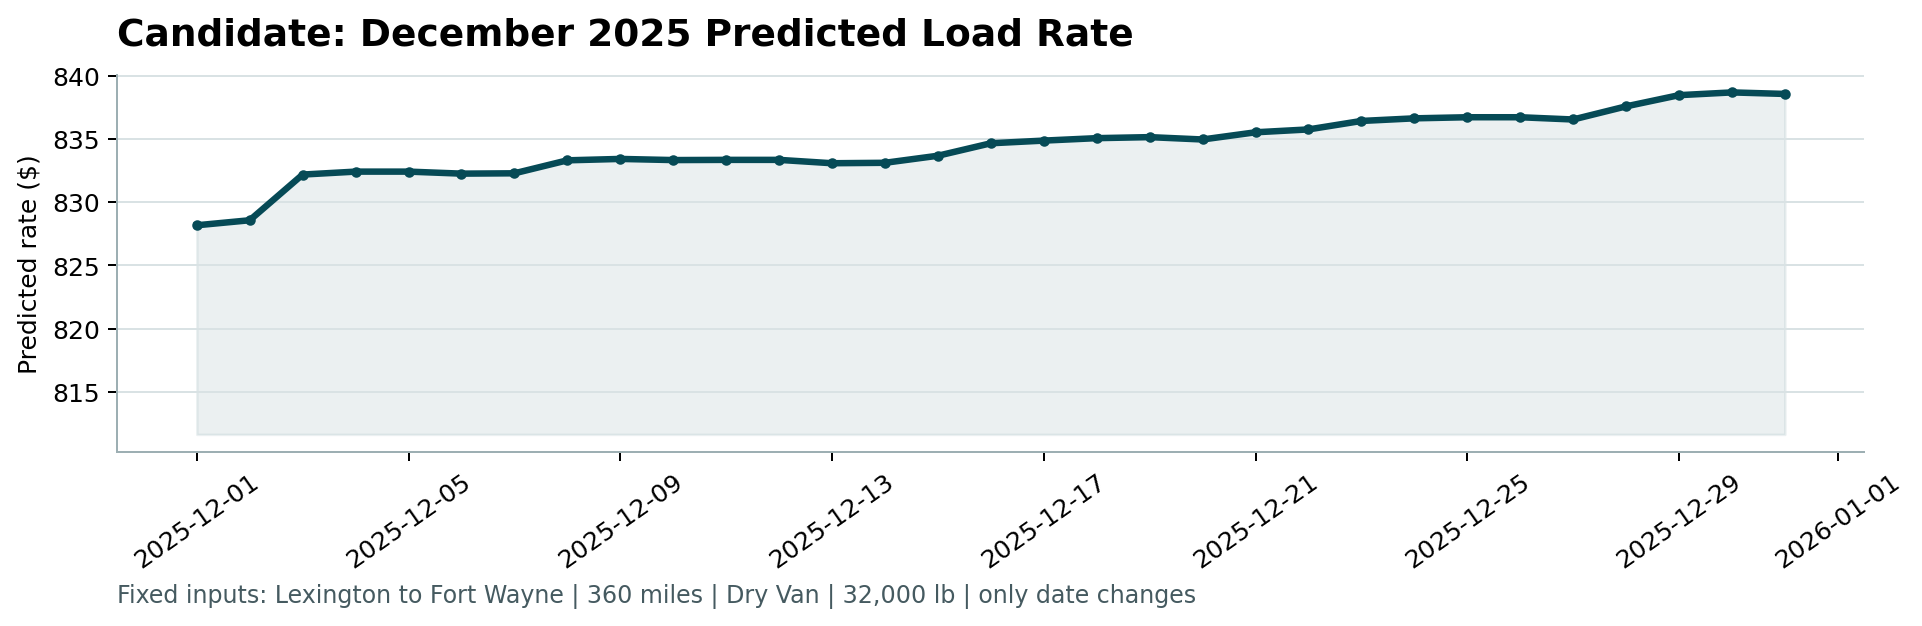

In [134]:
from IPython.display import Image, display

display(Image("scorer_results/candidate_december.png"))

In [135]:
from google.colab import files

files.download("validation_predictions.csv")
files.download("december_chart_inputs.csv")
files.download("scorer_results/candidate_december.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [136]:
!git config --global user.name "Harshalak02"
!git config --global user.email "karangaleharshal8@gmail.com"

In [137]:
!git clone https://github.com/Harshalak02/freight-rate-prediction

Cloning into 'freight-rate-prediction'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [138]:
from google.colab import files

uploaded = files.upload()

Saving validation_predictions.csv to validation_predictions (1).csv


In [139]:
from google.colab import files

uploaded = files.upload()

Saving december_chart_inputs.csv to december_chart_inputs (1).csv


In [140]:
from google.colab import files

uploaded = files.upload()

Saving Detailed_Freight_Rate_Prediction_Report.docx to Detailed_Freight_Rate_Prediction_Report.docx
Saving Detailed_Freight_Rate_Prediction_Report.pdf to Detailed_Freight_Rate_Prediction_Report.pdf
Saving candidate_december.png to candidate_december.png


In [ ]:
from google.colab import files

uploaded = files.upload()